# Marina Biodiversity GAT Pipeline (Final Clean Version)

Run cells top to bottom, in order. Do not skip cells.

---
**Updated in this version:**
- Prediction target changed from `species_count` (raw OBIS occurrence-record count) to `species_richness` (unique species count); the raw count is retained separately as a diagnostic-only `occurrence_record_count` column, never fed to any model.
- Current-informed edges are now symmetrized, and every node (including stagnant ones) is guaranteed `max_edges_per_node` edges via geographic-nearest-neighbor fallback/top-up.
- Added: geographic-kNN topology ablation, paired statistical significance testing (Wilcoxon, bootstrap CI, Cohen's d), hyperparameter sensitivity analysis, and land-cell handling strategy comparison (Steps 7f-7i).


## Step 1: Install packages

In [1]:
!pip install copernicusmarine torch_geometric fastapi uvicorn pyngrok --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 55.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 1.9 MB/s eta 0:00:00


## Step 2: RESTART SESSION NOW
Runtime -> Restart session, then continue from Step 3.

## Step 3: Copernicus Marine login

In [1]:
!copernicusmarine login

INFO - 2026-08-29T07:57:13Z - Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register
Copernicus Marine username: Jpriya
Copernicus Marine password: 
INFO - 2026-08-29T07:57:28Z - Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.


## Step 4: OBIS species data

In [3]:
%%writefile obis_ingest.py
"""
Module 1b: OBIS Species Occurrence Data Ingestion

Downloads ALL available OBIS occurrence records using pagination,
while writing each page directly to CSV instead of keeping the
entire dataset in RAM.

The final CSV remains compatible with the existing Marina-GAT pipeline.
"""

import os
import requests
import pandas as pd


def get_obis_occurrences(
    min_lat,
    max_lat,
    min_lon,
    max_lon,
    days_back=365,
    page_size=1000,
    output_csv="obis_occurrences.csv"
):
    """
    Download complete OBIS occurrence records using pagination.

    Records are written page-by-page to CSV to avoid keeping the
    complete dataset in memory.

    Returns:
        total_records
        unique_species
    """

    geometry = (
        f"POLYGON(({min_lon} {min_lat},{max_lon} {min_lat},"
        f"{max_lon} {max_lat},{min_lon} {max_lat},"
        f"{min_lon} {min_lat}))"
    )

    url = "https://api.obis.org/v3/occurrence"

    start_date = (
        pd.Timestamp.now().normalize()
        - pd.Timedelta(days=days_back)
    ).strftime("%Y-%m-%d")

    # Remove previous output so a new run starts cleanly
    if os.path.exists(output_csv):
        os.remove(output_csv)

    offset = 0
    page_number = 1
    total_records = 0
    unique_species = set()

    first_write = True

    while True:

        params = {
            "geometry": geometry,
            "size": page_size,
            "offset": offset,
            "startdate": start_date,
        }

        print(
            f"Downloading OBIS page {page_number} "
            f"(offset={offset}, size={page_size})..."
        )

        try:
            response = requests.get(
                url,
                params=params,
                timeout=60
            )

            response.raise_for_status()

        except requests.RequestException as e:
            print(f"\nOBIS request failed at offset {offset}: {e}")
            print("You can safely rerun the cell to restart the download.")
            raise

        results = response.json().get("results", [])

        # No more records
        if not results:
            print("\nNo more records returned.")
            break

        page_df = pd.DataFrame(results)

        # Keep the same columns expected by the existing Marina-GAT pipeline
        keep_cols = [
            c for c in [
                "scientificName",
                "decimalLatitude",
                "decimalLongitude",
                "eventDate",
                "individualCount",
                "species"
            ]
            if c in page_df.columns
        ]

        page_df = page_df[keep_cols]

        # Remove records without usable coordinates
        if (
            "decimalLatitude" in page_df.columns
            and "decimalLongitude" in page_df.columns
        ):
            page_df = page_df.dropna(
                subset=["decimalLatitude", "decimalLongitude"]
            )

        # Track unique species without storing all occurrence records
        species_column = None

        if "species" in page_df.columns:
            species_column = "species"
        elif "scientificName" in page_df.columns:
            species_column = "scientificName"

        if species_column is not None:
            species_values = (
                page_df[species_column]
                .dropna()
                .astype(str)
                .str.strip()
            )

            unique_species.update(
                x for x in species_values
                if x
            )

        # Write this page immediately to disk
        page_df.to_csv(
            output_csv,
            mode="w" if first_write else "a",
            header=first_write,
            index=False
        )

        first_write = False

        total_records += len(page_df)

        print(
            f"  Retrieved {len(page_df)} usable records "
            f"(total so far: {total_records})"
        )

        # If fewer than page_size were returned,
        # this is the final page.
        if len(results) < page_size:
            print("\nFinal page reached.")
            break

        offset += page_size
        page_number += 1

    print("\n==========================================")
    print("          OBIS DATA SUMMARY")
    print("==========================================")
    print(f"Study period          : Last {days_back} days")
    print(f"Total usable records  : {total_records:,}")
    print(f"Unique species        : {len(unique_species):,}")
    print(f"Pages downloaded      : {page_number:,}")
    print(f"Output file           : {output_csv}")
    print("==========================================")

    return total_records, len(unique_species)


if __name__ == "__main__":

    # India East Coast
    # Tamil Nadu + Andhra Pradesh + Odisha
    # Most recent 3-months OBIS window

    total_records, unique_species = get_obis_occurrences(
        min_lat=8.0,
        max_lat=21.5,
        min_lon=78.0,
        max_lon=87.5,
        days_back=90,
        page_size=1000,
        output_csv="obis_occurrences.csv"
    )

    print("\nOBIS ingestion completed successfully.")

Overwriting obis_ingest.py


In [4]:
!python obis_ingest.py

  Retrieved 217 usable records (total so far: 217)

Final page reached.

          OBIS DATA SUMMARY
Study period          : Last 90 days
Total usable records  : 217
Unique species        : 109
Pages downloaded      : 1
Output file           : obis_occurrences.csv

OBIS ingestion completed successfully.


## Step 5: Copernicus ocean physics data (India east coast)

In [5]:
%%writefile copernicus_ingest.py
"""
Module 1c: Copernicus Marine Real-Time Data Ingestion
Pulls SST, salinity, and current vectors (u,v) for the study area.

Two modes:
  - fetch_ocean_physics(...): single window (used by the spatial-only splits).
  - fetch_early_late_windows(...): TWO non-overlapping windows -- "early"
    and "late" -- needed for the temporal split. You
    train node features from the early window and test on the late window,
    which is the only honest way to ask "does this generalize forward in
    time" (a random or spatial split within one window can't answer that
    at all -- it never trains on the past and predicts the future).

SETUP (one-time, do this first in Colab):
  !pip install copernicusmarine
  Register free account: https://data.marine.copernicus.eu/register
  Then run: copernicusmarine login   (enter username/password when prompted)
"""
import copernicusmarine
import xarray as xr
import pandas as pd

PHYSICS_DATASET = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m"

DEFAULT_WINDOW_DAYS = 14   # length of each window (early and late)
DEFAULT_GAP_DAYS = 0       # optional gap between end of early window and start of late window


def fetch_ocean_physics(min_lon, max_lon, min_lat, max_lat, start_date, end_date,
                         out_path="ocean_physics.nc", target_grid_size=40):
    """Single-window pull. See module docstring."""
    copernicusmarine.subset(
        dataset_id=PHYSICS_DATASET,
        variables=["uo", "vo", "thetao", "so"],
        minimum_longitude=min_lon,
        maximum_longitude=max_lon,
        minimum_latitude=min_lat,
        maximum_latitude=max_lat,
        start_datetime=start_date,
        end_datetime=end_date,
        output_filename=out_path,
    )
    ds = xr.open_dataset(out_path)
    lat_n, lon_n = ds.dims["latitude"], ds.dims["longitude"]
    lat_factor = max(1, lat_n // target_grid_size)
    lon_factor = max(1, lon_n // target_grid_size)
    if lat_factor > 1 or lon_factor > 1:
        ds_coarse = ds.isel(
            latitude=slice(0, None, lat_factor), longitude=slice(0, None, lon_factor),
        ).load()
        ds.close()
        ds_coarse.to_netcdf(out_path)
        return ds_coarse
    return ds


def fetch_early_late_windows(min_lon, max_lon, min_lat, max_lat,
                              window_days=DEFAULT_WINDOW_DAYS, gap_days=DEFAULT_GAP_DAYS,
                              target_grid_size=40,
                              early_out="ocean_physics_early.nc",
                              late_out="ocean_physics_late.nc"):
    """
    Downloads two consecutive, non-overlapping windows over the SAME
    bounding box and grid target -- 'early' (further in the past) and
    'late' (closer to now) -- so a model trained on early-window features
    can be tested on late-window features at the same nodes.

    NOTE: because this uses the same target_grid_size logic independently
    for each window, the coarsened grids should align in practice, but
    always verify with align_grids() in graph_construction.py before
    trusting node-to-node correspondence across the two files.
    """
    now = pd.Timestamp.now().normalize()
    late_end = now
    late_start = late_end - pd.Timedelta(days=window_days)
    early_end = late_start - pd.Timedelta(days=gap_days)
    early_start = early_end - pd.Timedelta(days=window_days)

    print(f"Early window: {early_start.date()} -> {early_end.date()}")
    print(f"Late window:  {late_start.date()} -> {late_end.date()}")

    ds_early = fetch_ocean_physics(
        min_lon, max_lon, min_lat, max_lat,
        early_start.strftime("%Y-%m-%dT00:00:00"), early_end.strftime("%Y-%m-%dT00:00:00"),
        out_path=early_out, target_grid_size=target_grid_size,
    )
    ds_late = fetch_ocean_physics(
        min_lon, max_lon, min_lat, max_lat,
        late_start.strftime("%Y-%m-%dT00:00:00"), late_end.strftime("%Y-%m-%dT00:00:00"),
        out_path=late_out, target_grid_size=target_grid_size,
    )
    print(f"Early grid: {ds_early.dims['latitude']}x{ds_early.dims['longitude']}, "
          f"Late grid: {ds_late.dims['latitude']}x{ds_late.dims['longitude']}")
    if (ds_early.dims["latitude"], ds_early.dims["longitude"]) != \
       (ds_late.dims["latitude"], ds_late.dims["longitude"]):
        print("WARNING: early/late grids came back different shapes -- "
              "graph_construction.py's align_grids() will need to intersect "
              "them by coordinate before a temporal split will work.")
    return ds_early, ds_late


if __name__ == "__main__":
    # India east coast - Tamil Nadu, Andhra Pradesh, Odisha stretch
    # 1) full window (still produced, for the spatial-only splits)
    end = pd.Timestamp.now().normalize()
    start = end - pd.Timedelta(days=DEFAULT_WINDOW_DAYS)
    fetch_ocean_physics(
        min_lon=78.0, max_lon=87.5, min_lat=8.0, max_lat=21.5,
        start_date=start.strftime("%Y-%m-%dT00:00:00"),
        end_date=end.strftime("%Y-%m-%dT00:00:00"),
        out_path="ocean_physics.nc",
    )
    # 2) early/late windows (for the temporal split)
    fetch_early_late_windows(min_lon=78.0, max_lon=87.5, min_lat=8.0, max_lat=21.5)


Writing copernicus_ingest.py


In [6]:
!python copernicus_ingest.py

INFO - 2026-08-29T07:57:44Z - Selected dataset version: "202406"
INFO - 2026-08-29T07:57:44Z - Selected dataset part: "default"
100% 56/56 [00:34<00:00,  1.60it/s]
INFO - 2026-08-29T07:58:26Z - Total size of the download: 96.46 MB.
/content/copernicus_ingest.py:44: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  lat_n, lon_n = ds.dims["latitude"], ds.dims["longitude"]
Early window: 2026-08-01 -> 2026-08-15
Late window:  2026-08-15 -> 2026-08-29
INFO - 2026-08-29T07:58:31Z - Selected dataset version: "202406"
INFO - 2026-08-29T07:58:31Z - Selected dataset part: "default"
100% 56/56 [00:31<00:00,  1.77it/s]
INFO - 2026-08-29T07:59:06Z - Total size of the download: 96.46 MB.
/content/copernicus_ingest.py:44: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of d

In [7]:
# Also pull the early/late windows needed for the temporal split below.
from copernicus_ingest import fetch_early_late_windows
fetch_early_late_windows(min_lon=78.0, max_lon=87.5, min_lat=8.0, max_lat=21.5)


Early window: 2026-08-01 -> 2026-08-15
Late window:  2026-08-15 -> 2026-08-29


INFO - 2026-08-29T07:59:56Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-08-29T07:59:56Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"


  0%|          | [00:00<?]

INFO - 2026-08-29T08:00:31Z - Total size of the download: 96.46 MB.
INFO:copernicusmarine:Total size of the download: 96.46 MB.
/content/copernicus_ingest.py:44: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  lat_n, lon_n = ds.dims["latitude"], ds.dims["longitude"]
INFO - 2026-08-29T08:00:36Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-08-29T08:00:36Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"


  0%|          | [00:00<?]

INFO - 2026-08-29T08:01:11Z - Total size of the download: 96.46 MB.
INFO:copernicusmarine:Total size of the download: 96.46 MB.


Early grid: 41x58, Late grid: 41x58


/content/copernicus_ingest.py:44: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  lat_n, lon_n = ds.dims["latitude"], ds.dims["longitude"]
/content/copernicus_ingest.py:92: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"Early grid: {ds_early.dims['latitude']}x{ds_early.dims['longitude']}, "
/content/copernicus_ingest.py:93: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  f"Late grid: {ds_

(<xarray.Dataset> Size: 13MB
 Dimensions:    (time: 337, depth: 1, latitude: 41, longitude: 58)
 Coordinates:
   * time       (time) datetime64[ns] 3kB 2026-08-01 ... 2026-08-15
   * depth      (depth) float32 4B 0.494
   * latitude   (latitude) float32 164B 8.0 8.333 8.667 9.0 ... 20.67 21.0 21.33
   * longitude  (longitude) float32 232B 78.0 78.17 78.33 ... 87.17 87.33 87.5
 Data variables:
     uo         (time, depth, latitude, longitude) float32 3MB ...
     vo         (time, depth, latitude, longitude) float32 3MB ...
     thetao     (time, depth, latitude, longitude) float32 3MB ...
     so         (time, depth, latitude, longitude) float32 3MB ...
 Attributes:
     Conventions:               CF-1.8
     area:                      Global
     contact:                   https://marine.copernicus.eu/contact
     credit:                    E.U. Copernicus Marine Service Information (CM...
     institution:               Mercator Ocean International
     licence:                   h

**Note:** `copernicus_ingest.py` now also produces `ocean_physics_early.nc` and `ocean_physics_late.nc` (two non-overlapping time windows), used below by the temporal evaluation split. `graph_construction.py` now builds time-aggregated node features (mean/std/trend over the window) instead of a single snapshot, and `explainability.py`/`dashboard.py` were updated to match the new feature column names.

## Step 6: Graph construction (current-informed edges)

In [8]:
%%writefile graph_construction.py
"""
Module 2: Graph Construction with Current-Informed Edges
Builds a PyTorch Geometric graph where:
  - Nodes = grid cells across the marina zone, each with TIME-AGGREGATED
            ocean features computed across the full downloaded window
            (mean, variability, and trend per variable) rather than a
            single snapshot -- this is what gives the model something to
            learn beyond "the currents happened to look like X on one day".
  - Edges = connect regions ALONG the direction ocean currents actually flow,
            using the time-mean current (not simple geographic proximity)
            -- this is your novelty. Edges are symmetrized after selection
            and every node is guaranteed max_edges_per_node edges via a
            per-node geographic-nearest-neighbor fallback/top-up, so no
            node is left near-isolated and connectivity is directly
            comparable to a geographic-kNN baseline graph (see
            build_geographic_knn_edges below).

TARGET VARIABLE: species_richness (unique species observed near each node),
NOT species_count (raw OBIS occurrence-record count). An earlier version of
this pipeline used species_count as the prediction target, which conflates
true species diversity with historical sampling effort: a single heavily
observed species contributes to that count identically to fifty distinct
species each observed once. species_richness fixes this by counting DISTINCT
species per node instead. The raw occurrence count is still computed and
kept as a diagnostic-only column, occurrence_record_count, for the
sampling-effort analysis in the paper -- it is never fed into any model.
"""
import numpy as np
import pandas as pd
import xarray as xr
import torch
from torch_geometric.data import Data

# Node feature columns produced by build_node_features, in order.
# (species_richness is always last -- every model in this project excludes
# the last column as the prediction target; keep it last if you add features.)
FEATURE_COLUMNS = [
    "temp_mean", "temp_std", "temp_trend",
    "salinity_mean", "salinity_std",
    "u_mean", "u_std",
    "v_mean", "v_std",
    "current_speed_mean", "current_speed_std",
    "species_richness",
]


def _linear_trend(values):
    """Slope of a simple linear fit over the time axis; 0.0 if <2 valid points."""
    valid = ~np.isnan(values)
    if valid.sum() < 2:
        return 0.0
    t = np.arange(len(values))[valid]
    y = values[valid]
    slope, _ = np.polyfit(t, y, 1)
    return float(slope)


def build_node_features(physics_nc="ocean_physics.nc", obis_csv=None):
    """
    Create one node per (lat, lon) grid cell from the Copernicus time window.
    Each node feature = time-aggregated [temp, salinity, u, v, current speed]
    statistics (mean/std/trend) + species_richness, instead of a single
    snapshot's raw values. This requires copernicus_ingest.py to have pulled
    more than one timestep (see DEFAULT_WINDOW_DAYS there); if the file only
    has a single timestep, std/trend will come out as 0.0 for every node,
    which is a sign the ingest step needs a wider date range.
    """
    ds = xr.open_dataset(physics_nc)
    ds = ds.isel(depth=0) if "depth" in ds.dims else ds

    has_time = "time" in ds.sizes and ds.sizes["time"] > 1
    if not has_time:
        print("WARNING: only one timestep in ocean_physics.nc -- temporal "
              "features (std, trend) will be degenerate (all zero). Re-run "
              "copernicus_ingest.py with a wider date range to fix this.")

    lats = ds.latitude.values
    lons = ds.longitude.values

    nodes = []
    coords = []
    land_mask = []  # True = land/no-data cell (zero-filled), False = ocean cell
    for i, lat in enumerate(lats):
        for j, lon in enumerate(lons):
            if has_time:
                temp_series = ds.thetao.values[:, i, j]
                sal_series = ds.so.values[:, i, j]
                u_series = ds.uo.values[:, i, j]
                v_series = ds.vo.values[:, i, j]
            else:
                temp_series = np.array([ds.thetao.values[i, j]])
                sal_series = np.array([ds.so.values[i, j]])
                u_series = np.array([ds.uo.values[i, j]])
                v_series = np.array([ds.vo.values[i, j]])

            # land / missing-data guard: if every timestep is NaN, this is a
            # land cell -- zero out rather than dropping, so the grid stays
            # rectangular for the edge-construction step
            if np.all(np.isnan(temp_series)):
                nodes.append([0.0] * (len(FEATURE_COLUMNS) - 1) + [0])
                coords.append((lat, lon))
                land_mask.append(True)
                continue

            speed_series = np.sqrt(u_series ** 2 + v_series ** 2)

            temp_mean = float(np.nanmean(temp_series))
            temp_std = float(np.nanstd(temp_series))
            temp_trend = _linear_trend(temp_series)
            sal_mean = float(np.nanmean(sal_series))
            sal_std = float(np.nanstd(sal_series))
            u_mean = float(np.nanmean(u_series))
            u_std = float(np.nanstd(u_series))
            v_mean = float(np.nanmean(v_series))
            v_std = float(np.nanstd(v_series))
            speed_mean = float(np.nanmean(speed_series))
            speed_std = float(np.nanstd(speed_series))

            species_richness = 0  # filled in below if obis_csv given
            nodes.append([temp_mean, temp_std, temp_trend, sal_mean, sal_std,
                          u_mean, u_std, v_mean, v_std, speed_mean, speed_std,
                          species_richness])
            coords.append((lat, lon))
            land_mask.append(False)

    node_df = pd.DataFrame(nodes, columns=FEATURE_COLUMNS)
    coords_df = pd.DataFrame(coords, columns=["lat", "lon"])
    coords_df["is_land"] = land_mask
    # Diagnostic-only column, never fed to any model: the raw OBIS
    # occurrence-record count at this node, kept alongside species_richness
    # so the sampling-effort confound can still be inspected and reported
    # without being the thing that is actually predicted.
    node_df["occurrence_record_count"] = 0

    # Optional: attach species richness (unique species count) per nearest
    # grid cell from OBIS data. species_richness -- NOT
    # occurrence_record_count -- is FEATURE_COLUMNS[-1] and is therefore the
    # actual prediction target used by every model in this pipeline.
    if obis_csv is not None:
        try:
            obis = pd.read_csv(obis_csv)
        except FileNotFoundError:
            print(f"Warning: {obis_csv} not found, species_richness will be 0 for all nodes")
            return node_df, coords_df

        species_col = None
        if "species" in obis.columns:
            species_col = "species"
        elif "scientificName" in obis.columns:
            species_col = "scientificName"
        if species_col is None:
            print("Warning: OBIS data has no 'species'/'scientificName' column -- "
                  "cannot compute richness, species_richness will be 0 for all nodes. "
                  "occurrence_record_count will still be populated for diagnostic use.")

        for idx, row in coords_df.iterrows():
            nearby = obis[
                (abs(obis["decimalLatitude"] - row["lat"]) < 0.3) &
                (abs(obis["decimalLongitude"] - row["lon"]) < 0.3)
            ]
            node_df.loc[idx, "occurrence_record_count"] = len(nearby)
            if species_col is not None:
                unique_species = (
                    nearby[species_col].dropna().astype(str).str.strip()
                )
                unique_species = unique_species[unique_species != ""]
                node_df.loc[idx, "species_richness"] = unique_species.nunique()

    return node_df, coords_df


def build_current_informed_edges(coords_df, node_df, drift_threshold=0.02,
                                  max_edges_per_node=5, angle_tolerance_deg=45.0):
    """
    THE NOVELTY STEP.
    Connect node i -> node j if the TIME-MEAN ocean current at node i points
    TOWARD node j (within angle_tolerance_deg), rather than just because
    they're geographically close.

    This means biodiversity-relevant signal (larval drift, pollutant
    transport, nutrient flow) propagates along actual water movement paths
    instead of straight-line distance.

    Every node -- even a stagnant one whose current magnitude falls below
    drift_threshold -- ends up with exactly max_edges_per_node edges: current-
    direction candidates are used where available, and topped up (or
    entirely replaced, for stagnant nodes) with nearest-geographic-neighbor
    edges otherwise. All edges are symmetrized (i -> j implies j -> i) after
    selection. This guarantees the current-informed graph has the same
    per-node degree as a geographic-kNN graph built with the same
    max_edges_per_node, so the two topologies are comparable on equal
    footing (see build_geographic_knn_edges and the topology ablation below).
    """
    n = len(coords_df)
    coords_arr = coords_df[["lat", "lon"]].values
    uv_arr = node_df[["u_mean", "v_mean"]].values

    # precompute full pairwise distance matrix once (n is a few thousand at most)
    diffs = coords_arr[:, None, :] - coords_arr[None, :, :]
    dist_matrix = np.linalg.norm(diffs, axis=2)

    directed_pairs = set()

    for i in range(n):
        u, v = uv_arr[i]
        current_mag = np.sqrt(u**2 + v**2)

        chosen = np.array([], dtype=int)

        if current_mag >= drift_threshold:
            current_angle = np.arctan2(v, u)
            deltas = coords_arr - coords_arr[i]
            target_angles = np.arctan2(deltas[:, 0], deltas[:, 1])
            angle_diff = np.abs(np.arctan2(np.sin(target_angles - current_angle),
                                            np.cos(target_angles - current_angle)))
            tol = np.radians(angle_tolerance_deg)
            candidates = np.where(angle_diff < tol)[0]
            candidates = candidates[candidates != i]
            if len(candidates) > 0:
                dists = dist_matrix[i, candidates]
                chosen = candidates[np.argsort(dists)[:max_edges_per_node]]

        if len(chosen) < max_edges_per_node:
            # geographic-nearest-neighbor fallback/top-up -- guarantees every
            # node gets max_edges_per_node edges, same as a baseline graph
            dists_all = dist_matrix[i].copy()
            dists_all[i] = np.inf
            dists_all[chosen] = np.inf
            n_more = max_edges_per_node - len(chosen)
            extra = np.argsort(dists_all)[:n_more]
            chosen = np.concatenate([chosen, extra]).astype(int)

        for j in chosen:
            directed_pairs.add((i, int(j)))
            directed_pairs.add((int(j), i))  # symmetrize

    sym_pairs = sorted(directed_pairs)
    edge_index = torch.tensor(sym_pairs, dtype=torch.long).t().contiguous()
    edge_attr = torch.ones((edge_index.shape[1], 1), dtype=torch.float)

    return edge_index, edge_attr


def build_geographic_knn_edges(coords_df, max_edges_per_node=5):
    """
    Baseline topology for the ablation in Section 4.7: every node connects
    to its max_edges_per_node nearest geographic neighbors, with no
    reference to current direction at all. Edges are symmetrized the same
    way as build_current_informed_edges, so per-node degree matches exactly
    -- the only difference between the two graphs is WHICH neighbors are
    chosen, not HOW MANY.
    """
    n = len(coords_df)
    coords_arr = coords_df[["lat", "lon"]].values
    diffs = coords_arr[:, None, :] - coords_arr[None, :, :]
    dist_matrix = np.linalg.norm(diffs, axis=2)

    directed_pairs = set()
    for i in range(n):
        dists = dist_matrix[i].copy()
        dists[i] = np.inf
        chosen = np.argsort(dists)[:max_edges_per_node]
        for j in chosen:
            directed_pairs.add((i, int(j)))
            directed_pairs.add((int(j), i))

    sym_pairs = sorted(directed_pairs)
    edge_index = torch.tensor(sym_pairs, dtype=torch.long).t().contiguous()
    edge_attr = torch.ones((edge_index.shape[1], 1), dtype=torch.float)
    return edge_index, edge_attr


def build_graph(physics_nc="ocean_physics.nc", obis_csv="obis_occurrences.csv",
                 topology="current_informed", land_handling="zero_fill",
                 drift_threshold=0.02, max_edges_per_node=5, angle_tolerance_deg=45.0):
    """
    topology: "current_informed" (default, novelty graph) or "geographic_knn"
              (baseline for the topology ablation).
    land_handling: "zero_fill" (default -- keep zero-filled land nodes in the
              grid), "remove" (drop land nodes before graph construction), or
              "valid_mask" (keep zero-filled land nodes but add a binary
              is_valid feature column so the model can learn to discount them).
    """
    node_df, coords_df = build_node_features(physics_nc, obis_csv)

    if land_handling == "remove":
        keep = ~coords_df["is_land"].values
        node_df = node_df.loc[keep].reset_index(drop=True)
        coords_df = coords_df.loc[keep].reset_index(drop=True)
    elif land_handling == "valid_mask":
        node_df["is_valid"] = (~coords_df["is_land"]).astype(float)
    elif land_handling != "zero_fill":
        raise ValueError(f"Unknown land_handling: {land_handling}")

    if topology == "current_informed":
        edge_index, edge_attr = build_current_informed_edges(
            coords_df, node_df, drift_threshold=drift_threshold,
            max_edges_per_node=max_edges_per_node,
            angle_tolerance_deg=angle_tolerance_deg)
    elif topology == "geographic_knn":
        edge_index, edge_attr = build_geographic_knn_edges(
            coords_df, max_edges_per_node=max_edges_per_node)
    else:
        raise ValueError(f"Unknown topology: {topology}")

    # feature columns actually fed to the model: FEATURE_COLUMNS, plus
    # is_valid if land_handling == "valid_mask". occurrence_record_count is
    # NEVER included here -- diagnostic only.
    model_columns = list(FEATURE_COLUMNS)
    if "is_valid" in node_df.columns:
        model_columns = model_columns[:-1] + ["is_valid"] + [model_columns[-1]]

    x = torch.tensor(node_df[model_columns].values, dtype=torch.float)
    data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr)
    data.coords = coords_df  # keep for later map plotting / explainability
    data.feature_names = model_columns
    if "occurrence_record_count" in node_df.columns:
        data.occurrence_record_count = torch.tensor(
            node_df["occurrence_record_count"].values, dtype=torch.float)

    print(f"Graph built: {data.num_nodes} nodes, {data.num_edges} {topology} edges, "
          f"{len(model_columns) - 1} input features/node (+ species_richness target); "
          f"land_handling={land_handling}")
    return data


def align_graphs_by_coords(graph_a, graph_b, tol=1e-6):
    """
    Needed for the temporal split: two graphs built from
    different .nc files (different time windows) can, in principle, come
    back with slightly different grids after independent coarsening. This
    intersects both graphs' node coordinates and returns REINDEXED
    (graph_a_aligned, graph_b_aligned) so node i in one corresponds to
    node i in the other. Edges are rebuilt for each aligned graph from its
    own (now node-count-matching) coordinates/features -- edges are NOT
    assumed to be shared, since current direction is time-window-specific.

    Raises if fewer than 10 nodes survive the intersection (not enough to
    do anything useful with).
    """
    a = graph_a.coords.round(6)
    b = graph_b.coords.round(6)
    merged = a.reset_index().merge(b.reset_index(), on=["lat", "lon"], suffixes=("_a", "_b"))
    if len(merged) < 10:
        raise ValueError(f"Only {len(merged)} nodes align by coordinate between the two "
                          f"graphs -- grids likely came back different shapes/extents. "
                          f"Re-check fetch_early_late_windows' bounding box/target_grid_size.")

    idx_a = merged["index_a"].values
    idx_b = merged["index_b"].values

    def _subset(graph, idx):
        x = graph.x[idx]
        coords = graph.coords.iloc[idx].reset_index(drop=True)
        node_df = pd.DataFrame(x.numpy(), columns=graph.feature_names)
        edge_index, edge_attr = build_current_informed_edges(coords, node_df)
        out = Data(x=x, edge_index=edge_index, edge_attr=edge_attr)
        out.coords = coords
        out.feature_names = graph.feature_names
        return out

    return _subset(graph_a, idx_a), _subset(graph_b, idx_b)


if __name__ == "__main__":
    graph = build_graph("ocean_physics.nc")
    print(graph)


Writing graph_construction.py


In [9]:
!python graph_construction.py

Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
Data(x=[2378, 12], edge_index=[2, 19190], edge_attr=[19190, 1], coords=            lat        lon  is_land
0      8.000000  78.000000    False
1      8.000000  78.166687    False
2      8.000000  78.333344    False
3      8.000000  78.500000    False
4      8.000000  78.666687    False
...         ...        ...      ...
2373  21.333336  86.833344     True
2374  21.333336  87.000000    False
2375  21.333336  87.166687    False
2376  21.333336  87.333344    False
2377  21.333336  87.500000    False

[2378 rows x 3 columns], feature_names=[12], occurrence_record_count=[2378])


## Step 7: Train GAT model

In [10]:
%%writefile gat_model.py
"""
Module 3: Spatial Graph Attention Network (GAT)
Predicts an OBIS-derived species-richness signal (species_richness) per
region node, using
attention over current-informed edges. Attention weights double as
explainability output (Module 4 will visualize them).
"""
import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from graph_construction import build_graph


class MarinaGAT(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels=16, heads=4):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=0.3)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1,
                             concat=False, dropout=0.3)
        self.out = torch.nn.Linear(hidden_channels, 1)  # predict species_richness

    def forward(self, x, edge_index, return_attention=False):
        # drop species_richness (last column) - it's the prediction target, not
        # a feature. Leaving it in lets the model see the answer directly.
        x = x[:, :-1]
        x, attn1 = self.gat1(x, edge_index, return_attention_weights=True)
        x = F.elu(x)
        x, attn2 = self.gat2(x, edge_index, return_attention_weights=True)
        x = F.elu(x)
        out = self.out(x)

        if return_attention:
            return out, (attn1, attn2)
        return out


def train_model(graph, epochs=100, lr=0.01):
    # in_channels - 1: species_richness is excluded inside forward()
    model = MarinaGAT(in_channels=graph.x.shape[1] - 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)

    raw_target = graph.x[:, -1:].clone()

    # simple train/test split across nodes
    n = graph.num_nodes
    perm = torch.randperm(n)
    train_idx = perm[: int(0.8 * n)]
    test_idx = perm[int(0.8 * n):]

    # LEAKAGE FIX (vs. original): target used to be normalized with
    # raw_target.mean()/.std() over ALL nodes (train + test) before the
    # split existed. Now computed from train_idx only, same convention as
    # evaluation_splits.py, and applied to both train and test.
    train_mean = raw_target[train_idx].mean()
    train_std = raw_target[train_idx].std() + 1e-6
    target = (raw_target - train_mean) / train_std

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(graph.x, graph.edge_index)
        loss = F.mse_loss(pred[train_idx], target[train_idx])
        loss.backward()
        optimizer.step()

        if epoch % 20 == 0:
            model.eval()
            with torch.no_grad():
                test_pred = model(graph.x, graph.edge_index)
                test_loss = F.mse_loss(test_pred[test_idx], target[test_idx])
            print(f"Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss.item():.4f}")

    return model


if __name__ == "__main__":
    graph = build_graph("ocean_physics.nc")
    model = train_model(graph)

    # save for later use in dashboard / explainability module
    torch.save(model.state_dict(), "marina_gat.pt")
    print("\nModel saved to marina_gat.pt")

    # quick sanity check: run inference + get attention weights
    model.eval()
    with torch.no_grad():
        preds, attention = model(graph.x, graph.edge_index, return_attention=True)
    print(f"\nSample predictions (species richness) for first 5 nodes:")
    print(preds[:5].squeeze())


Writing gat_model.py


In [11]:
!python gat_model.py

Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
Epoch   0 | Train Loss: 2.0674 | Test Loss: 10.2179
Epoch  20 | Train Loss: 1.2970 | Test Loss: 3.1076
Epoch  40 | Train Loss: 1.0017 | Test Loss: 2.6639
Epoch  60 | Train Loss: 0.9644 | Test Loss: 2.6133
Epoch  80 | Train Loss: 0.9506 | Test Loss: 2.6245

Model saved to marina_gat.pt

Sample predictions (species richness) for first 5 nodes:
tensor([-0.0332, -0.0327, -0.0362, -0.0379, -0.0380])


## Step 7b: Baseline comparisons (GCN + Linear Regression vs GAT)
Two weaker baselines to show what attention and graph structure are actually buying you:
- **GCN** — same graph, same current-informed edges, but uniform neighbor averaging instead of learned attention.
- **Linear Regression** — no graph at all, predicts from each node's own features only.

All three are trained and evaluated on the *same* train/test node split for a fair comparison.

In [12]:
%%writefile gcn_model.py
"""
Module 3b: Baseline GCN (no attention) for comparison against MarinaGAT.
Same graph, same task, same train loop shape — only the conv layer changes,
so any performance gap is attributable to attention, not to some other
confound (different features, different split, different optimizer).
"""
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from graph_construction import build_graph


class MarinaGCN(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels=16):
        super().__init__()
        self.gcn1 = GCNConv(in_channels, hidden_channels)
        self.gcn2 = GCNConv(hidden_channels, hidden_channels)
        self.out = torch.nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index):
        # drop species_richness (last column) - it's the prediction target,
        # not a feature (mirrors the exclusion in MarinaGAT / LinearBaseline)
        x = x[:, :-1]
        x = F.elu(self.gcn1(x, edge_index))
        x = F.dropout(x, p=0.2, training=self.training)
        x = F.elu(self.gcn2(x, edge_index))
        return self.out(x)


def train_gcn(graph, train_idx, test_idx, target, epochs=100, lr=0.01):
    # in_channels - 1: species_richness is excluded inside forward()
    model = MarinaGCN(in_channels=graph.x.shape[1] - 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(graph.x, graph.edge_index)
        loss = F.mse_loss(pred[train_idx], target[train_idx])
        loss.backward()
        optimizer.step()

        if epoch % 20 == 0:
            model.eval()
            with torch.no_grad():
                test_pred = model(graph.x, graph.edge_index)
                test_loss = F.mse_loss(test_pred[test_idx], target[test_idx])
            print(f"[GCN] Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss.item():.4f}")

    return model


Writing gcn_model.py


In [13]:
%%writefile linreg_baseline.py
"""
Module 3d: Linear Regression baseline — no graph, no message passing.
Predicts biodiversity score from each node's own raw features only
(temp, salinity, u, v). Ignores the current-informed edges completely.
This is the weakest sensible baseline: if GAT can't beat this, the
graph structure isn't earning its keep.
"""
import torch
import torch.nn.functional as F


class LinearBaseline(torch.nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        # exclude species_richness (last column) - that's the target, not a feature
        self.linear = torch.nn.Linear(in_channels - 1, 1)

    def forward(self, x, edge_index=None):  # edge_index accepted but unused, kept for API symmetry
        feats = x[:, :-1]
        return self.linear(feats)


def train_linreg(graph, train_idx, test_idx, target, epochs=100, lr=0.01):
    model = LinearBaseline(in_channels=graph.x.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(graph.x)
        loss = F.mse_loss(pred[train_idx], target[train_idx])
        loss.backward()
        optimizer.step()

        if epoch % 20 == 0:
            model.eval()
            with torch.no_grad():
                test_pred = model(graph.x)
                test_loss = F.mse_loss(test_pred[test_idx], target[test_idx])
            print(f"[LinReg] Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss.item():.4f}")

    return model


Writing linreg_baseline.py


In [14]:
%%writefile compare_models.py
"""
Module 3e: GAT vs Linear Regression comparison on the identical
train/test split -- an ablation check for whether the current-informed
graph (with attention) beats a no-graph baseline.

LEAKAGE FIX (vs. original): target mean/std were previously computed from
raw_target.mean()/.std() over ALL nodes (train + test) before the split.
Fixed to use train-only stats, same convention as evaluation_splits.py.
"""
import torch
import torch.nn.functional as F
from graph_construction import build_graph
from gat_model import MarinaGAT
from linreg_baseline import LinearBaseline, train_linreg

torch.manual_seed(42)  # fix split so every model sees the exact same nodes

graph = build_graph("ocean_physics.nc")

raw_target = graph.x[:, -1:].clone()

n = graph.num_nodes
perm = torch.randperm(n)
train_idx = perm[: int(0.8 * n)]
test_idx = perm[int(0.8 * n):]

# --- LEAKAGE FIX: normalize using TRAIN stats only, apply to both sides ---
train_mean = raw_target[train_idx].mean()
train_std = raw_target[train_idx].std() + 1e-6
target = (raw_target - train_mean) / train_std

print("=== Training GAT ===")
# in_channels - 1: species_richness excluded inside MarinaGAT.forward()
gat_model = MarinaGAT(in_channels=graph.x.shape[1] - 1)
optimizer = torch.optim.Adam(gat_model.parameters(), lr=0.01, weight_decay=5e-4)
for epoch in range(100):
    gat_model.train()
    optimizer.zero_grad()
    pred = gat_model(graph.x, graph.edge_index)
    loss = F.mse_loss(pred[train_idx], target[train_idx])
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0:
        gat_model.eval()
        with torch.no_grad():
            test_pred = gat_model(graph.x, graph.edge_index)
            if isinstance(test_pred, tuple):
                test_pred = test_pred[0]
            test_loss = F.mse_loss(test_pred[test_idx], target[test_idx])
        print(f"[GAT] Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Test Loss: {test_loss.item():.4f}")

print("\n=== Training Linear Regression (no-graph baseline) ===")
linreg_model = train_linreg(graph, train_idx, test_idx, target)


def final_metrics(model, name):
    model.eval()
    with torch.no_grad():
        if isinstance(model, LinearBaseline):
            pred = model(graph.x)
        else:
            pred = model(graph.x, graph.edge_index)
        if isinstance(pred, tuple):
            pred = pred[0]
    test_pred = pred[test_idx].squeeze()
    test_true = target[test_idx].squeeze()
    mse = F.mse_loss(test_pred, test_true).item()
    mae = F.l1_loss(test_pred, test_true).item()
    print(f"{name:>7} | Test MSE: {mse:.4f} | Test MAE: {mae:.4f}")
    return mse, mae


print("\n=== Final comparison (held-out test nodes) ===")
final_metrics(gat_model, "GAT")
final_metrics(linreg_model, "LinReg")


Writing compare_models.py


In [15]:
!python compare_models.py

Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
=== Training GAT ===
[GAT] Epoch   0 | Train Loss: 16.8524 | Test Loss: 0.5219
[GAT] Epoch  20 | Train Loss: 1.0352 | Test Loss: 0.2190
[GAT] Epoch  40 | Train Loss: 1.0056 | Test Loss: 0.1124
[GAT] Epoch  60 | Train Loss: 0.9650 | Test Loss: 0.0924
[GAT] Epoch  80 | Train Loss: 0.9571 | Test Loss: 0.1026

=== Training Linear Regression (no-graph baseline) ===
[LinReg] Epoch   0 | Train Loss: 71.7524 | Test Loss: 66.0266
[LinReg] Epoch  20 | Train Loss: 1.0596 | Test Loss: 0.2288
[LinReg] Epoch  40 | Train Loss: 1.5977 | Test Loss: 0.5166
[LinReg] Epoch  60 | Train Loss: 1.1600 | Test Loss: 0.2458
[LinReg] Epoch  80 | Train Loss: 1.0516 | Test Loss: 0.1268

=== Final comparison (held-out test nodes) ===
    GAT | Test MSE: 0.1066 | Test MAE: 0.1637
 LinReg | Test MSE: 0.1195 | Test MAE: 0.2024


## Step 7c: Charts and tables for the paper


In [16]:
%%writefile results_plots.py
"""
Module 3f: Generates publication-ready figures + a metrics table from the
GAT vs LinReg (vs GCN, if present) comparison. Run this AFTER compare_models.py
so it can reuse the same trained models and test split.

LEAKAGE FIX (vs. original): target mean/std were previously computed from
raw_target.mean()/.std() over ALL nodes (train + test) before the split,
then applied to both sides -- test-set values leaked into the scale used
for the training loss. Fixed the same way evaluation_splits.py fixes it:
stats are computed from train_idx only and applied to both train and test.
Test-side numbers now reflect genuinely unseen-scale generalization, not
just unseen values on a scale the model was indirectly told about.

Produces (saved to ./figures/):
  - metrics_bar_chart.png   (grouped bar chart: MSE, MAE per model)
  - loss_curves.png         (train/test loss vs epoch, per model)
  - pred_vs_true_scatter.png (held-out predictions vs ground truth)
  - results_table.png       (clean table image for direct paper insertion)
  - results_table.csv       (same table, raw values for LaTeX/Word import)
"""
import os
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib
matplotlib.use("Agg")

from graph_construction import build_graph
from gat_model import MarinaGAT
from linreg_baseline import LinearBaseline, train_linreg

try:
    from gcn_model import MarinaGCN, train_gcn
    HAS_GCN = True
except ImportError:
    HAS_GCN = False

os.makedirs("figures", exist_ok=True)
torch.manual_seed(42)

graph = build_graph("ocean_physics.nc")
raw_target = graph.x[:, -1:].clone()

n = graph.num_nodes
perm = torch.randperm(n)
train_idx = perm[: int(0.8 * n)]
test_idx = perm[int(0.8 * n):]

# --- LEAKAGE FIX: normalize using TRAIN stats only, apply to both sides ---
train_mean = raw_target[train_idx].mean()
train_std = raw_target[train_idx].std() + 1e-6
target = (raw_target - train_mean) / train_std

results = {}  # name -> dict(mse, mae, train_losses, test_losses, pred)


def eval_model(model, name, is_linreg=False):
    model.eval()
    with torch.no_grad():
        pred = model(graph.x) if is_linreg else model(graph.x, graph.edge_index)
        if isinstance(pred, tuple):
            pred = pred[0]
    test_pred = pred[test_idx].squeeze()
    test_true = target[test_idx].squeeze()
    mse = F.mse_loss(test_pred, test_true).item()
    mae = F.l1_loss(test_pred, test_true).item()
    results[name] = {"mse": mse, "mae": mae,
                      "pred": test_pred.numpy(), "true": test_true.numpy()}
    return mse, mae


# --- Train GAT, logging per-epoch losses ---
print("=== Training GAT ===")
gat_model = MarinaGAT(in_channels=graph.x.shape[1] - 1)
optimizer = torch.optim.Adam(gat_model.parameters(), lr=0.01, weight_decay=5e-4)
gat_train_losses, gat_test_losses, gat_epochs = [], [], []
for epoch in range(100):
    gat_model.train()
    optimizer.zero_grad()
    pred = gat_model(graph.x, graph.edge_index)
    if isinstance(pred, tuple):
        pred = pred[0]
    loss = F.mse_loss(pred[train_idx], target[train_idx])
    loss.backward()
    optimizer.step()
    if epoch % 5 == 0:
        gat_model.eval()
        with torch.no_grad():
            tp = gat_model(graph.x, graph.edge_index)
            if isinstance(tp, tuple):
                tp = tp[0]
            tloss = F.mse_loss(tp[test_idx], target[test_idx])
        gat_epochs.append(epoch)
        gat_train_losses.append(loss.item())
        gat_test_losses.append(tloss.item())
eval_model(gat_model, "GAT")
results["GAT"]["train_curve"] = (gat_epochs, gat_train_losses)
results["GAT"]["test_curve"] = (gat_epochs, gat_test_losses)

# --- GCN (optional, only if the file is still present in this Colab session) ---
if HAS_GCN:
    print("\n=== Training GCN ===")
    gcn_model = train_gcn(graph, train_idx, test_idx, target)
    eval_model(gcn_model, "GCN")

# --- Linear Regression ---
print("\n=== Training Linear Regression ===")
linreg_model = train_linreg(graph, train_idx, test_idx, target)
eval_model(linreg_model, "LinReg", is_linreg=True)

# ==== everything below is unchanged from the original file ====

import pandas as pd
import numpy as np

model_names = list(results.keys())

# --- metrics_bar_chart.png ---
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
mses = [results[m]["mse"] for m in model_names]
maes = [results[m]["mae"] for m in model_names]
ax[0].bar(model_names, mses, color=["#2b6cb0", "#48bb78", "#a0aec0"][:len(model_names)])
ax[0].set_title("Test MSE"); ax[0].set_ylabel("MSE (normalized)")
ax[1].bar(model_names, maes, color=["#2b6cb0", "#48bb78", "#a0aec0"][:len(model_names)])
ax[1].set_title("Test MAE"); ax[1].set_ylabel("MAE (normalized)")
fig.tight_layout()
fig.savefig("figures/metrics_bar_chart.png", dpi=200)
plt.close(fig)

# --- loss_curves.png ---
if "train_curve" in results.get("GAT", {}):
    fig, ax = plt.subplots(figsize=(6, 4))
    ep, tr = results["GAT"]["train_curve"]
    _, te = results["GAT"]["test_curve"]
    ax.plot(ep, tr, label="GAT train")
    ax.plot(ep, te, label="GAT test")
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE loss"); ax.legend()
    fig.tight_layout()
    fig.savefig("figures/loss_curves.png", dpi=200)
    plt.close(fig)

# --- pred_vs_true_scatter.png ---
fig, axes = plt.subplots(1, len(model_names), figsize=(4.5 * len(model_names), 4.2), sharey=True)
if len(model_names) == 1:
    axes = [axes]
for ax, name in zip(axes, model_names):
    ax.scatter(results[name]["true"], results[name]["pred"], alpha=0.6, s=15)
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("True (normalized)")
axes[0].set_ylabel("Predicted (normalized)")
fig.tight_layout()
fig.savefig("figures/pred_vs_true_scatter.png", dpi=200)
plt.close(fig)

# --- results_table.csv / .png ---
table_df = pd.DataFrame({
    "Model": model_names,
    "Test MSE": [results[m]["mse"] for m in model_names],
    "Test MAE": [results[m]["mae"] for m in model_names],
})
table_df.to_csv("figures/results_table.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 1 + 0.4 * len(model_names)))
ax.axis("off")
tbl = ax.table(cellText=table_df.round(4).values, colLabels=table_df.columns,
                loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.5)
fig.tight_layout()
fig.savefig("figures/results_table.png", dpi=200, bbox_inches="tight")
plt.close(fig)

print("\nSaved figures/metrics_bar_chart.png, loss_curves.png, "
      "pred_vs_true_scatter.png, results_table.png, results_table.csv")
print(table_df)


Writing results_plots.py


In [17]:
!python results_plots.py


Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
=== Training GAT ===

=== Training GCN ===
[GCN] Epoch   0 | Train Loss: 1.1740 | Test Loss: 1.4850
[GCN] Epoch  20 | Train Loss: 1.0367 | Test Loss: 0.1292
[GCN] Epoch  40 | Train Loss: 0.9930 | Test Loss: 0.0913
[GCN] Epoch  60 | Train Loss: 0.9714 | Test Loss: 0.0818
[GCN] Epoch  80 | Train Loss: 0.9704 | Test Loss: 0.0853

=== Training Linear Regression ===
[LinReg] Epoch   0 | Train Loss: 1.7547 | Test Loss: 0.2954
[LinReg] Epoch  20 | Train Loss: 1.1065 | Test Loss: 0.1510
[LinReg] Epoch  40 | Train Loss: 1.0545 | Test Loss: 0.1302
[LinReg] Epoch  60 | Train Loss: 1.0281 | Test Loss: 0.1161
[LinReg] Epoch  80 | Train Loss: 1.0164 | Test Loss: 0.1126

Saved figures/metrics_bar_chart.png, loss_curves.png, pred_vs_true_scatter.png, results_table.png, results_table.csv
    Model  Test MSE  Test MAE
0     GAT  0.106621  0.163653
1     GCN  0.089114  0.1559

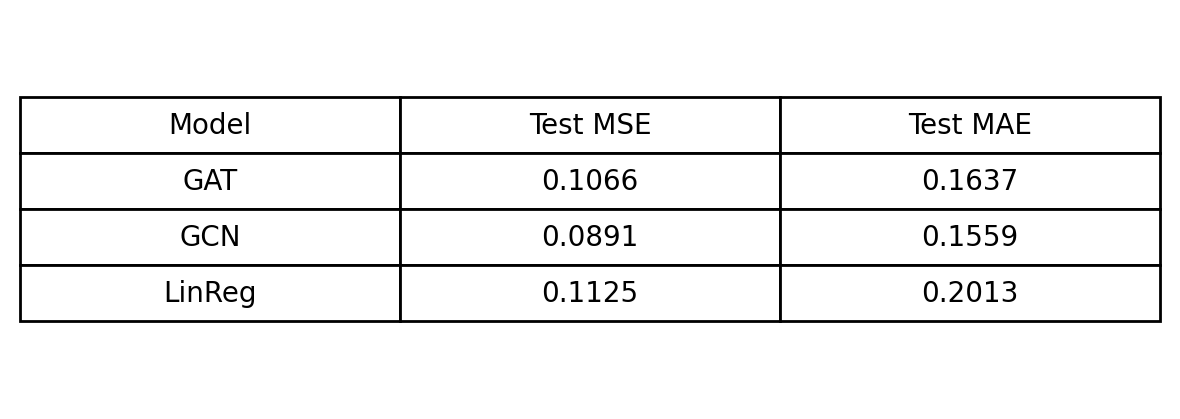

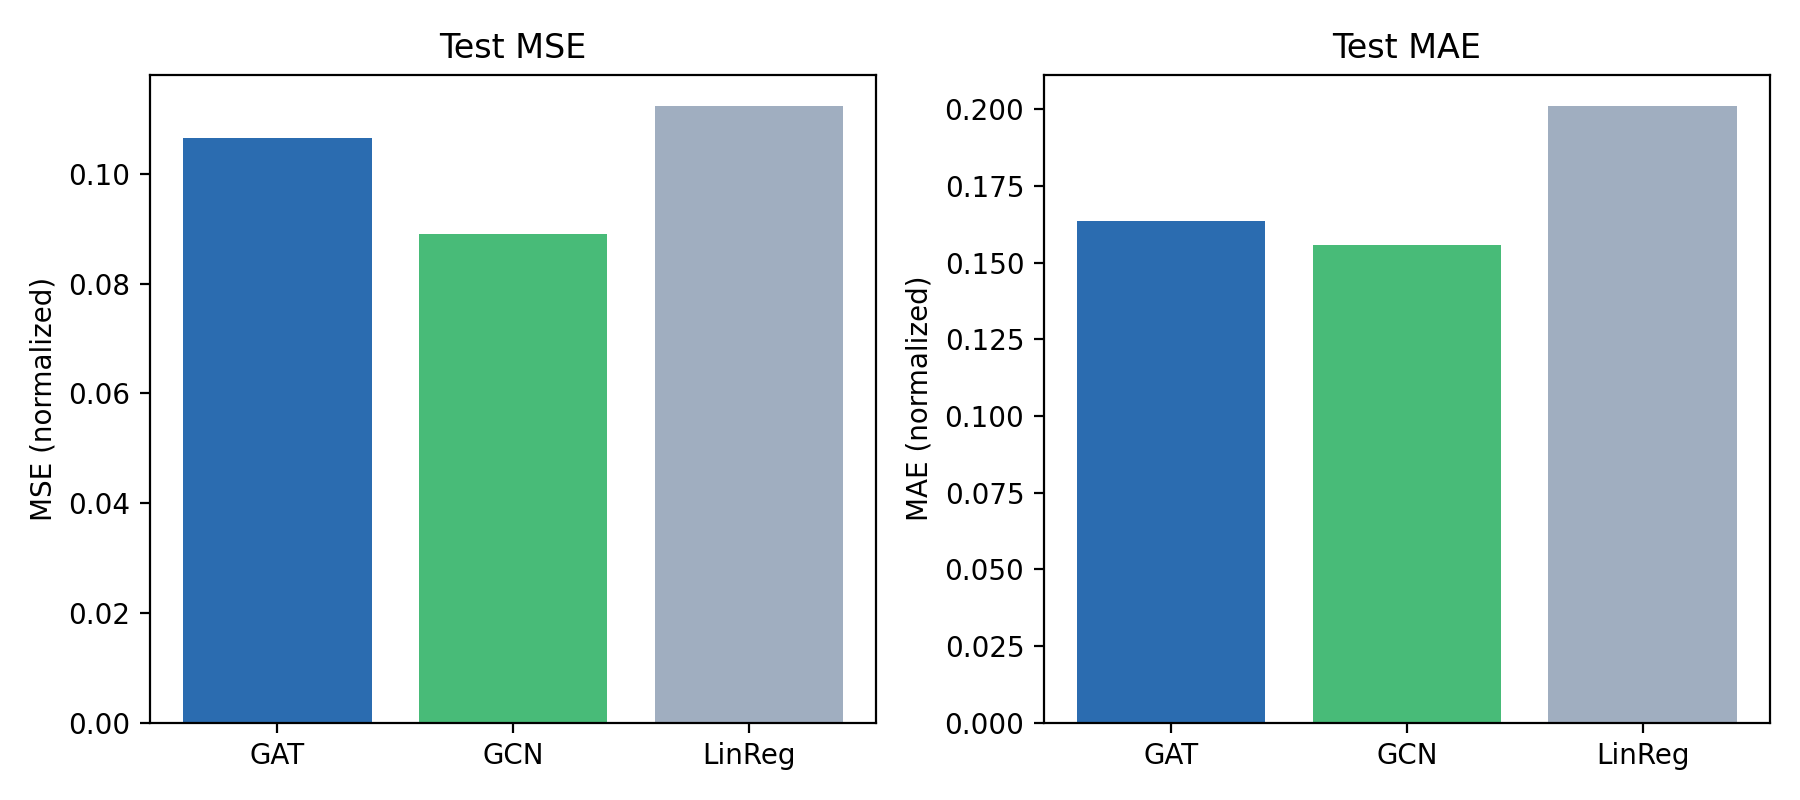

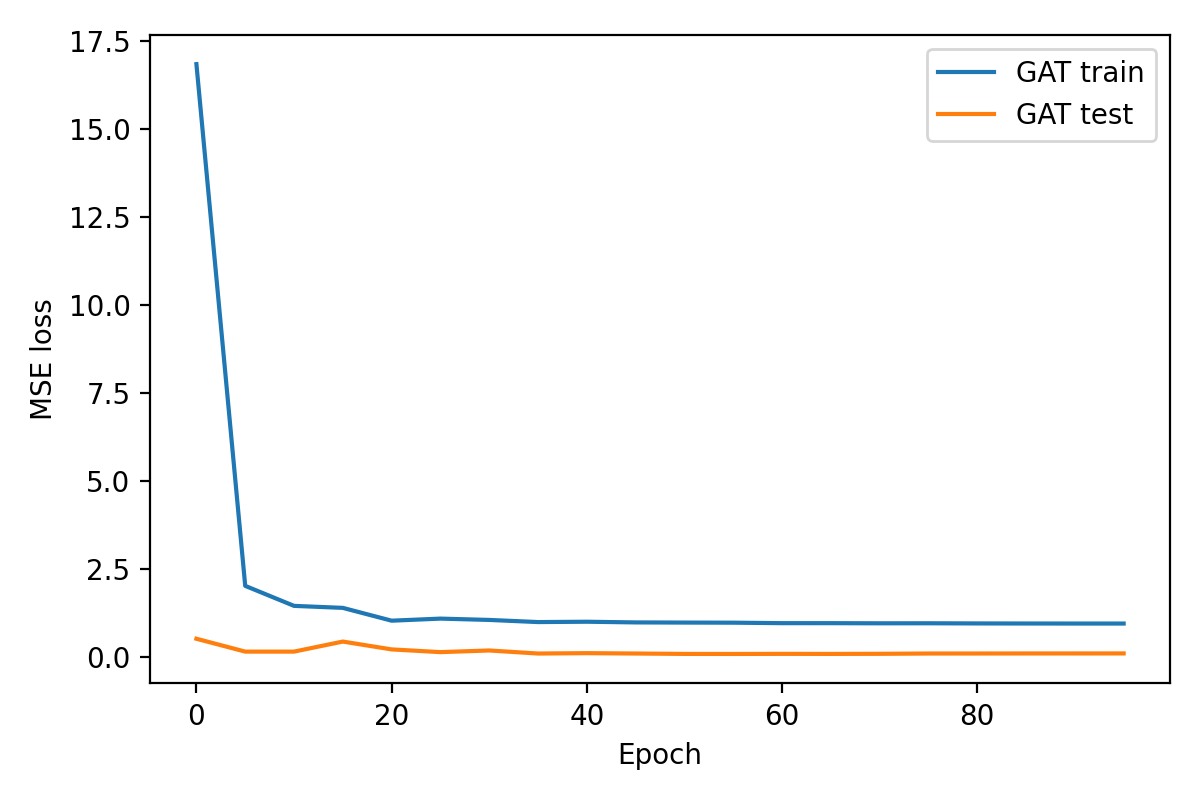

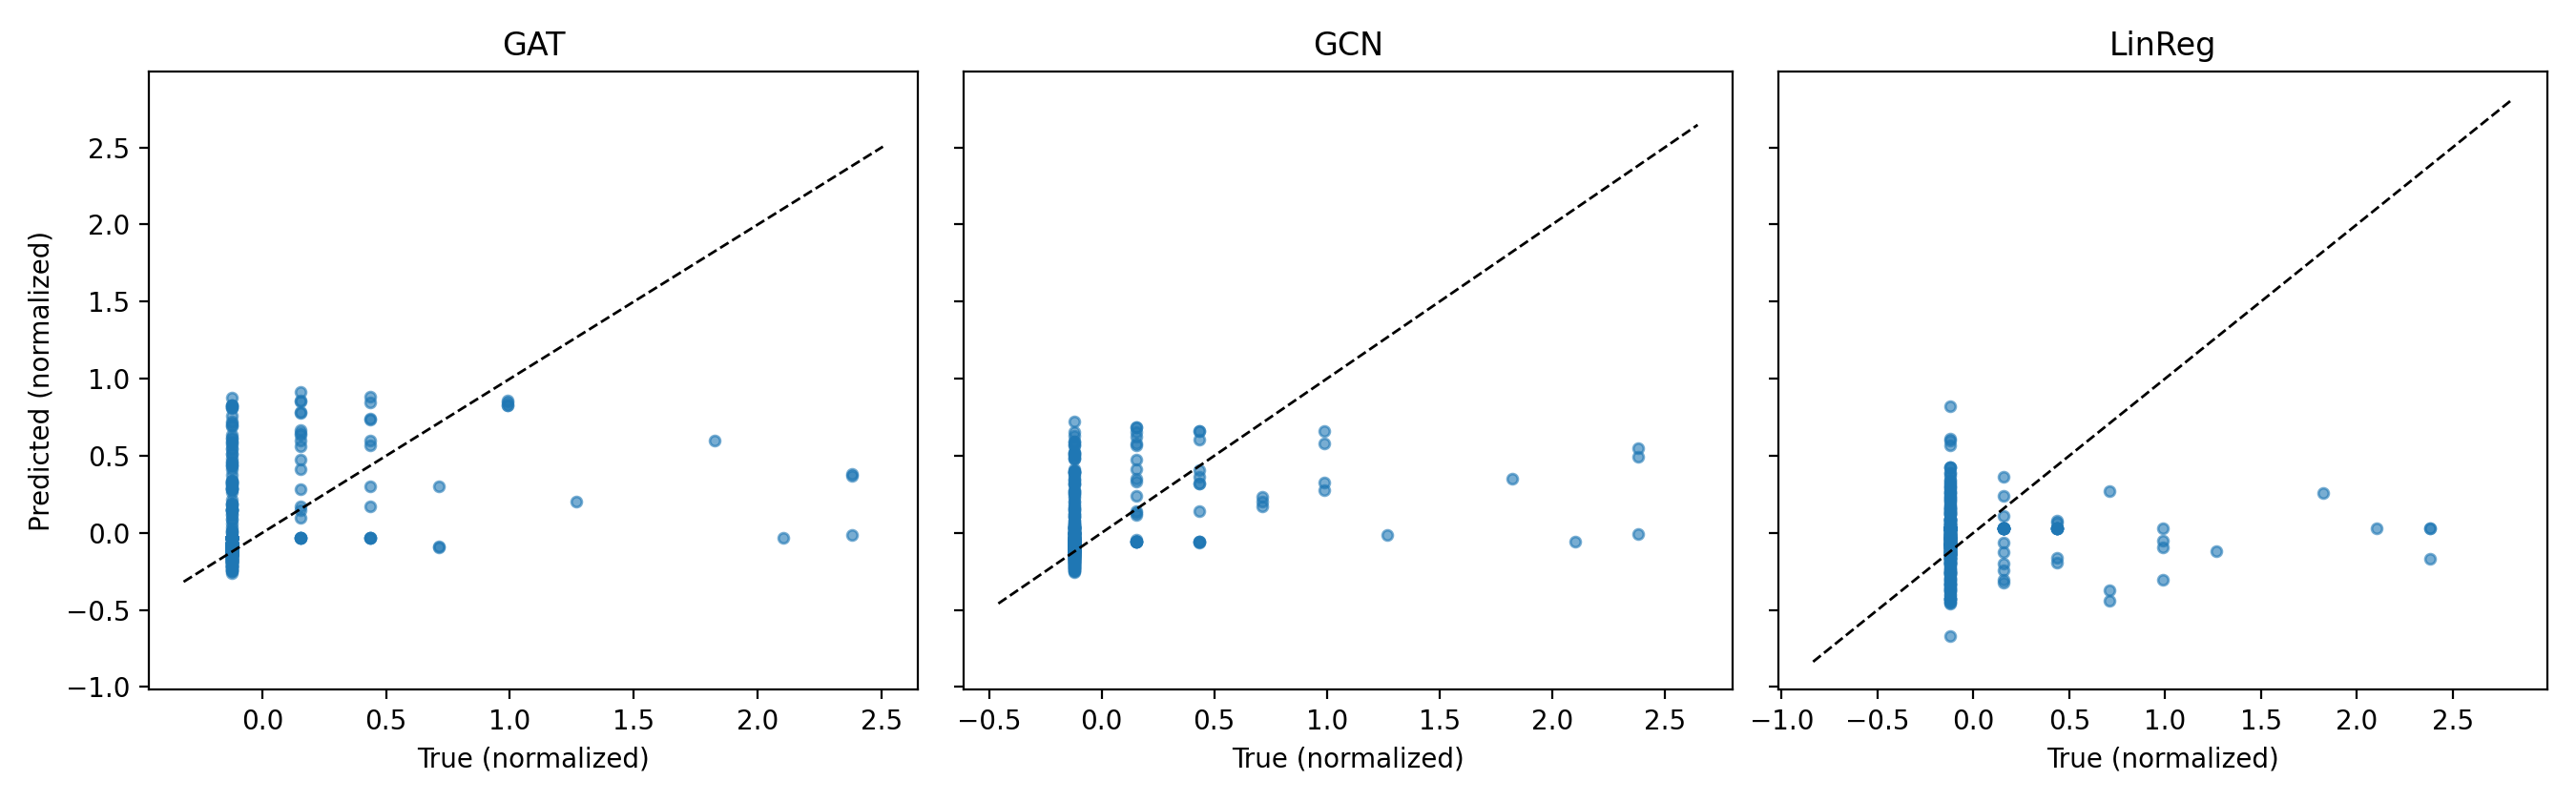

In [18]:
from IPython.display import Image, display
display(Image("figures/results_table.png"))
display(Image("figures/metrics_bar_chart.png"))
display(Image("figures/loss_curves.png"))
display(Image("figures/pred_vs_true_scatter.png"))


## Step 7d: Evaluation splits, weakest to strongest

`compare_models.py` above uses a single random 80/20 split over nodes --
optimistic, since neighboring grid cells are near-duplicates. The cells
below run two increasingly strict tests of generalization and report both
side by side, so no single (possibly favorable) split gets treated
as the final word:

1. **Spatial block split** -- k-fold over spatial blocks; every block gets
   tested on once. Tests generalization to nearby-but-unseen locations.
2. **Temporal split** -- train on an earlier time window's features, test
   on a later window's, at the same locations. Tests generalization
   forward in time.

Report the **strictest split your data supports** as the headline number,
not the weakest one that happens to look best.


**Leakage fix applied to `spatial_cv.py` and `evaluation_splits.py` below:**
1. *Message-passing leakage* -- training previously forwarded the full graph (train + held-out nodes together) and only masked the loss to `train_idx`. Since GATConv/GCNConv aggregate from graph neighbors, held-out node **features** could leak into train-node representations during training, even though held-out **labels** never entered the loss -- undercutting the "never seen in training" claim for the spatial block split. Fixed by forwarding only the node-induced subgraph over `train_idx` during training (`build_train_subgraph`); full-graph forward is still used at eval time, which is fine since that's inference, not a gradient step.
2. *Target normalization leakage* -- mean/std for normalizing the target were previously computed over train+test together. Fixed to use train-indices-only statistics, applied to both sides of the split.

The temporal split already used two physically separate graph objects for train vs. test, so it never had the message-passing issue.


In [19]:
%%writefile spatial_cv.py
"""
Module 3g: Spatial block cross-validation for GAT vs GCN vs LinReg.

WHY THIS EXISTS (replaces compare_models.py's single random node split):
Grid-cell nodes are spatially autocorrelated -- a node at (13.0N, 80.2E) has
nearly identical temp/salinity/current values to its neighbor at (13.05N,
80.2E). A *random* train/test split over nodes puts near-duplicate cells on
both sides of the split, so a model can "cheat" by memorizing local
conditions instead of learning anything generalizable. Reported test
MSE from a random split will look better than the model actually is.

This module instead:
  1. Bins nodes into spatial blocks (a coarse lat/lon grid over the study
     area, independent of the graph's own node grid).
  2. Assigns whole blocks -- never individual nodes -- to train or test,
     so no test node is a near-neighbor of a train node.
  3. Repeats across multiple block-fold assignments AND multiple random
     seeds (which reseed model init + block-to-fold assignment), and
     reports mean +/- std, not a single point estimate.

LEAKAGE FIXES (both were present in the original version of this file):
  a) Message passing across the train/test boundary. GATConv/GCNConv
     aggregate each node's representation from its graph neighbors. Simply
     computing loss on pred[train_idx] while forwarding the FULL graph
     (train_idx and test_idx together) lets held-out node FEATURES leak
     into train node representations during training, even though held-out
     LABELS never enter the loss. Fix: during training, forward only the
     node-induced subgraph over train_idx (build_train_subgraph below), so
     test nodes and their edges are structurally absent from the training
     computation graph. At eval time we forward the full graph -- that's
     fine and realistic (a deployed model gets to see surrounding regions'
     features at inference time; it just never trained on this fold's
     held-out labels or feature-derived gradients).
  b) Target normalization computed from train+test together. mean()/std()
     over the whole graph's target column let test-set target values shape
     the scale used for the training loss. Fix: normalize using train-only
     statistics (train_target_stats), applied to both train and test.

Usage:
    python spatial_cv.py
Produces:
    figures/spatial_cv_results.csv   (per-run rows: model, seed, fold, mse, mae)
    figures/spatial_cv_summary.csv   (mean +/- std per model)
    figures/spatial_cv_summary.png   (bar chart with error bars)
"""
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from torch_geometric.utils import subgraph

from graph_construction import build_graph
from gat_model import MarinaGAT
from gcn_model import MarinaGCN
from linreg_baseline import LinearBaseline

N_LAT_BLOCKS = 4      # coarse spatial binning grid for CV blocks
N_LON_BLOCKS = 4
N_FOLDS = 5            # blocks are partitioned into this many held-out folds
SEEDS = [0, 1, 2, 3, 4]
EPOCHS_GAT = 250
EPOCHS_OTHER = 100


def assign_blocks(coords_df, n_lat_blocks=N_LAT_BLOCKS, n_lon_blocks=N_LON_BLOCKS):
    """Bin each node into a coarse (lat_bin, lon_bin) spatial block id."""
    lat_bins = pd.cut(coords_df["lat"], bins=n_lat_blocks, labels=False)
    lon_bins = pd.cut(coords_df["lon"], bins=n_lon_blocks, labels=False)
    block_id = lat_bins.astype(int) * n_lon_blocks + lon_bins.astype(int)
    return block_id.values


def spatial_kfold_splits(block_ids, n_folds, seed):
    """
    Yield (train_idx, test_idx) node-index arrays, n_folds times, where
    every node in a given spatial block always lands entirely in either
    the train or the test side of a given fold.
    """
    rng = np.random.RandomState(seed)
    unique_blocks = np.unique(block_ids)
    rng.shuffle(unique_blocks)

    block_folds = np.array_split(unique_blocks, n_folds)

    for k in range(n_folds):
        test_blocks = set(block_folds[k].tolist())
        test_mask = np.array([b in test_blocks for b in block_ids])
        test_idx = np.where(test_mask)[0]
        train_idx = np.where(~test_mask)[0]
        if len(test_idx) == 0 or len(train_idx) == 0:
            continue
        yield torch.tensor(train_idx, dtype=torch.long), torch.tensor(test_idx, dtype=torch.long)


def compute_metrics(pred, true):
    pred = pred.squeeze()
    true = true.squeeze()
    mse = F.mse_loss(pred, true).item()
    mae = F.l1_loss(pred, true).item()
    return mse, mae


def train_target_stats(raw_target, idx_train):
    """Mean/std computed from TRAIN nodes only -- never from test nodes."""
    train_vals = raw_target[idx_train]
    return train_vals.mean(), train_vals.std() + 1e-6


def build_train_subgraph(graph, idx_train):
    """
    Node-induced subgraph over idx_train only: test nodes and any edge
    touching a test node are structurally absent, so a training forward
    pass cannot let GAT/GCN message-pass test-node features into train
    representations. relabel_nodes=True renumbers surviving nodes
    0..len(idx_train)-1 in the order of idx_train, which matches the row
    order of graph.x[idx_train] used below.
    """
    edge_index_train, _ = subgraph(
        idx_train, graph.edge_index, relabel_nodes=True, num_nodes=graph.num_nodes
    )
    x_train = graph.x[idx_train]
    return x_train, edge_index_train


def train_and_eval_gat(graph, train_idx, test_idx, raw_target, seed):
    torch.manual_seed(seed)
    mean, std = train_target_stats(raw_target, train_idx)
    target = (raw_target - mean) / std

    x_train, edge_index_train = build_train_subgraph(graph, train_idx)
    target_train = target[train_idx]

    model = MarinaGAT(in_channels=graph.x.shape[1] - 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
    for _ in range(EPOCHS_GAT):
        model.train()
        optimizer.zero_grad()
        pred = model(x_train, edge_index_train)
        loss = F.mse_loss(pred, target_train)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        # Full graph at eval time is fine: this is inference, not training --
        # no gradient step ever sees test-node information.
        pred_full = model(graph.x, graph.edge_index)
    return compute_metrics(pred_full[test_idx], target[test_idx])


def train_and_eval_gcn(graph, train_idx, test_idx, raw_target, seed):
    torch.manual_seed(seed)
    mean, std = train_target_stats(raw_target, train_idx)
    target = (raw_target - mean) / std

    x_train, edge_index_train = build_train_subgraph(graph, train_idx)
    target_train = target[train_idx]

    model = MarinaGCN(in_channels=graph.x.shape[1] - 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(EPOCHS_OTHER):
        model.train()
        optimizer.zero_grad()
        pred = model(x_train, edge_index_train)
        loss = F.mse_loss(pred, target_train)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        pred_full = model(graph.x, graph.edge_index)
    return compute_metrics(pred_full[test_idx], target[test_idx])


def train_and_eval_linreg(graph, train_idx, test_idx, raw_target, seed):
    # No message passing here (no graph convolution), so there's no
    # feature-leakage channel to fix -- but keep train-only normalization
    # for consistency with the other two models.
    torch.manual_seed(seed)
    mean, std = train_target_stats(raw_target, train_idx)
    target = (raw_target - mean) / std

    model = LinearBaseline(in_channels=graph.x.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(EPOCHS_OTHER):
        model.train()
        optimizer.zero_grad()
        pred = model(graph.x[train_idx])
        loss = F.mse_loss(pred, target[train_idx])
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        pred_full = model(graph.x)
    return compute_metrics(pred_full[test_idx], target[test_idx])


def run_spatial_cv():
    os.makedirs("figures", exist_ok=True)
    graph = build_graph("ocean_physics.nc")
    raw_target = graph.x[:, -1:].clone()  # NOTE: kept unnormalized here -- each
    # fold now normalizes using its own train_idx inside the trainers above.

    block_ids = assign_blocks(graph.coords)
    n_blocks = len(np.unique(block_ids))
    print(f"Spatial CV: {graph.num_nodes} nodes grouped into {n_blocks} spatial blocks, "
          f"{N_FOLDS} folds x {len(SEEDS)} seeds")
    if n_blocks < N_FOLDS:
        print(f"WARNING: only {n_blocks} distinct spatial blocks but N_FOLDS={N_FOLDS}. "
              "Some folds will be skipped -- results below are still valid but come "
              "from fewer than N_FOLDS x len(SEEDS) runs. Consider a smaller grid "
              "(fewer nodes) needs coarser N_LAT_BLOCKS/N_LON_BLOCKS, or a larger "
              "study area / finer node grid needs more blocks.")

    rows = []
    trainers = {"GAT": train_and_eval_gat, "GCN": train_and_eval_gcn, "LinReg": train_and_eval_linreg}

    for seed in SEEDS:
        for fold, (train_idx, test_idx) in enumerate(spatial_kfold_splits(block_ids, N_FOLDS, seed)):
            for name, trainer in trainers.items():
                mse, mae = trainer(graph, train_idx, test_idx, raw_target, seed)
                rows.append({"model": name, "seed": seed, "fold": fold,
                             "n_train": len(train_idx), "n_test": len(test_idx),
                             "mse": mse, "mae": mae})
                print(f"[{name}] seed={seed} fold={fold} "
                      f"n_train={len(train_idx)} n_test={len(test_idx)} "
                      f"MSE={mse:.4f} MAE={mae:.4f}")

    df = pd.DataFrame(rows)
    df.to_csv("figures/spatial_cv_results.csv", index=False)

    summary = df.groupby("model").agg(
        mse_mean=("mse", "mean"), mse_std=("mse", "std"), mse_median=("mse", "median"),
        mae_mean=("mae", "mean"), mae_std=("mae", "std"), mae_median=("mae", "median"),
        n_runs=("mse", "size"),
    ).reset_index()
    summary.to_csv("figures/spatial_cv_summary.csv", index=False)
    print("\n=== Spatial CV summary across folds x seeds ===")
    for _, r in summary.iterrows():
        print(f"{r['model']:>7} | MSE: {r['mse_mean']:.4f} +/- {r['mse_std']:.4f} "
              f"(median {r['mse_median']:.4f}) "
              f"| MAE: {r['mae_mean']:.4f} +/- {r['mae_std']:.4f} "
              f"(median {r['mae_median']:.4f}) "
              f"| n_runs: {int(r['n_runs'])}")

    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    colors = {"GAT": "#2b6cb0", "GCN": "#48bb78", "LinReg": "#a0aec0"}
    for ax, metric, title in zip(
        axes, ["mse", "mae"],
        ["Test MSE (lower better)", "Test MAE (lower better)"],
    ):
        means = [summary.loc[summary["model"] == m, f"{metric}_mean"].values[0] for m in trainers]
        stds = [summary.loc[summary["model"] == m, f"{metric}_std"].values[0] for m in trainers]
        ax.bar(list(trainers.keys()), means, yerr=stds, capsize=4,
               color=[colors[m] for m in trainers])
        ax.set_title(title, fontsize=10)

    fig.suptitle(f"Spatial block CV, {N_FOLDS} folds x {len(SEEDS)} seeds", fontsize=11)
    fig.tight_layout()
    fig.savefig("figures/spatial_cv_summary.png", dpi=200)
    plt.close(fig)
    print("\nSaved figures/spatial_cv_results.csv, spatial_cv_summary.csv, spatial_cv_summary.png")
    return df, summary


if __name__ == "__main__":
    run_spatial_cv()


Writing spatial_cv.py


In [20]:
%%writefile evaluation_splits.py
"""
Module 3h: Evaluation splits, from weakest to strongest test of generalization.

  1. Spatial block split  -- k-fold over spatial blocks (what spatial_cv.py
     already did). Blocks rotate through train/test; every block is tested
     on exactly once per seed. Tests: "does this generalize to nearby but
     unseen locations, on average?"

  2. Temporal split        -- train on node features from an EARLIER time
     window, test on the SAME nodes' features from a LATER window (same
     species_richness target throughout, since richness is computed once
     from the full OBIS record set and is not re-collected per window).
     Tests: "does this generalize forward in
     time, at known locations?" Requires copernicus_ingest.py's
     fetch_early_late_windows() to have been run.

LEAKAGE FIXES (both present in the original version of this file):
  a) Message passing across the train/test boundary. Split 1 forwarded the
     FULL graph (train and held-out nodes together) during training and
     only masked the LOSS to train_idx. Since GATConv/GCNConv aggregate
     each node from its graph neighbors, that let held-out node FEATURES
     leak into train representations during training. Fix: train_and_eval_*
     now forward only the node-induced subgraph over idx_train (see
     build_train_subgraph) during training, and use the full graph only at
     eval time (fine -- that's inference, not a gradient step). Split 2
     (temporal) already used two physically separate graph objects for
     train vs. test, so it never had this problem.
  b) Target normalization computed from train+test together (split 1
     called normalized_target(graph) once over the whole graph before
     splitting). Fix: normalization stats are now computed from idx_train
     only and applied to both sides of the split.

Both report MSE/MAE mean+-std -- same conventions as spatial_cv.py so
results are comparable across split types.

Usage:
    python evaluation_splits.py
Produces:
    figures/all_splits_results.csv     (every individual run)
    figures/all_splits_summary.csv     (per split-type x model)
    figures/all_splits_summary.png     (mean MSE by split type, GAT vs GCN vs LinReg)
"""
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from torch_geometric.utils import subgraph

from graph_construction import build_graph, align_graphs_by_coords
from gat_model import MarinaGAT
from gcn_model import MarinaGCN
from linreg_baseline import LinearBaseline

N_LAT_BLOCKS = 4
N_LON_BLOCKS = 4
N_FOLDS = 5
SEEDS = [0, 1, 2, 3, 4]
EPOCHS_GAT = 250
EPOCHS_OTHER = 100

TRAINERS = {}  # filled in below, model name -> train_and_eval fn


# ---------- shared helpers (same conventions as spatial_cv.py) ----------

def assign_blocks(coords_df, n_lat_blocks=N_LAT_BLOCKS, n_lon_blocks=N_LON_BLOCKS):
    lat_bins = pd.cut(coords_df["lat"], bins=n_lat_blocks, labels=False)
    lon_bins = pd.cut(coords_df["lon"], bins=n_lon_blocks, labels=False)
    return (lat_bins.astype(int) * n_lon_blocks + lon_bins.astype(int)).values


def compute_metrics(pred, true):
    pred, true = pred.squeeze(), true.squeeze()
    mse = F.mse_loss(pred, true).item()
    mae = F.l1_loss(pred, true).item()
    return mse, mae


def normalized_target(graph):
    """
    Used ONLY for split 2 (temporal), where train and test are already two
    physically separate graphs (graph_early / graph_late) -- normalizing
    each with its own stats doesn't feed test information back into any
    training gradient, it only rescales how that side's metrics are
    reported. Split 1 uses train_target_stats() below instead, since
    there train and test share one graph/index space.
    """
    raw = graph.x[:, -1:].clone()
    return (raw - raw.mean()) / (raw.std() + 1e-6)


def train_target_stats(raw_target, idx_train):
    """Mean/std from TRAIN indices only -- never from held-out indices."""
    train_vals = raw_target[idx_train]
    return train_vals.mean(), train_vals.std() + 1e-6


def build_train_subgraph(graph, idx_train):
    """
    Node-induced subgraph over idx_train: held-out nodes and any edge
    touching one are structurally absent, so training can't message-pass
    held-out features into train representations. relabel_nodes=True
    renumbers surviving nodes 0..len(idx_train)-1 in idx_train's order,
    matching graph.x[idx_train]'s row order.
    """
    edge_index_train, _ = subgraph(
        idx_train, graph.edge_index, relabel_nodes=True, num_nodes=graph.num_nodes
    )
    x_train = graph.x[idx_train]
    return x_train, edge_index_train


def train_and_eval_gat(graph_train, idx_train, graph_test, idx_test, raw_target_train, raw_target_test, seed):
    torch.manual_seed(seed)

    # Train side always normalizes from train indices only, whether train
    # and test share one graph (split 1) or are different graphs (split 2,
    # temporal).
    mean, std = train_target_stats(raw_target_train, idx_train)
    target_train_full = (raw_target_train - mean) / std
    target_test_full = (raw_target_test - raw_target_test.mean()) / (raw_target_test.std() + 1e-6) \
        if raw_target_train is not raw_target_test else target_train_full

    x_train, edge_index_train = build_train_subgraph(graph_train, idx_train)
    target_train = target_train_full[idx_train]

    model = MarinaGAT(in_channels=graph_train.x.shape[1] - 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=5e-4)
    n_epochs = min(EPOCHS_GAT, 120)
    for _ in range(n_epochs):
        model.train(); optimizer.zero_grad()
        pred = model(x_train, edge_index_train)
        loss = F.mse_loss(pred, target_train)
        loss.backward(); optimizer.step()
    model.eval()
    with torch.no_grad():
        pred_full = model(graph_test.x, graph_test.edge_index)
    return compute_metrics(pred_full[idx_test], target_test_full[idx_test])


def train_and_eval_gcn(graph_train, idx_train, graph_test, idx_test, raw_target_train, raw_target_test, seed):
    torch.manual_seed(seed)
    mean, std = train_target_stats(raw_target_train, idx_train)
    target_train_full = (raw_target_train - mean) / std
    target_test_full = (raw_target_test - raw_target_test.mean()) / (raw_target_test.std() + 1e-6) \
        if raw_target_train is not raw_target_test else target_train_full

    x_train, edge_index_train = build_train_subgraph(graph_train, idx_train)
    target_train = target_train_full[idx_train]

    model = MarinaGCN(in_channels=graph_train.x.shape[1] - 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(EPOCHS_OTHER):
        model.train(); optimizer.zero_grad()
        pred = model(x_train, edge_index_train)
        loss = F.mse_loss(pred, target_train)
        loss.backward(); optimizer.step()
    model.eval()
    with torch.no_grad():
        pred_full = model(graph_test.x, graph_test.edge_index)
    return compute_metrics(pred_full[idx_test], target_test_full[idx_test])


def train_and_eval_linreg(graph_train, idx_train, graph_test, idx_test, raw_target_train, raw_target_test, seed):
    # No graph convolution -> no message-passing leak channel, but keep
    # train-only normalization for consistency/comparability.
    torch.manual_seed(seed)
    mean, std = train_target_stats(raw_target_train, idx_train)
    target_train_full = (raw_target_train - mean) / std
    target_test_full = (raw_target_test - raw_target_test.mean()) / (raw_target_test.std() + 1e-6) \
        if raw_target_train is not raw_target_test else target_train_full

    model = LinearBaseline(in_channels=graph_train.x.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(EPOCHS_OTHER):
        model.train(); optimizer.zero_grad()
        pred = model(graph_train.x[idx_train])
        loss = F.mse_loss(pred, target_train_full[idx_train])
        loss.backward(); optimizer.step()
    model.eval()
    with torch.no_grad():
        pred_full = model(graph_test.x)
    return compute_metrics(pred_full[idx_test], target_test_full[idx_test])


TRAINERS = {"GAT": train_and_eval_gat, "GCN": train_and_eval_gcn, "LinReg": train_and_eval_linreg}


# ---------- split 1: spatial block k-fold ----------

def run_spatial_block(graph, raw_target, rows):
    block_ids = assign_blocks(graph.coords)
    for seed in SEEDS:
        rng = np.random.RandomState(seed)
        blocks = np.unique(block_ids); rng.shuffle(blocks)
        folds = np.array_split(blocks, N_FOLDS)
        for fold, test_blocks in enumerate(folds):
            test_mask = np.isin(block_ids, test_blocks)
            idx_test = torch.tensor(np.where(test_mask)[0], dtype=torch.long)
            idx_train = torch.tensor(np.where(~test_mask)[0], dtype=torch.long)
            if len(idx_test) == 0 or len(idx_train) == 0:
                continue
            for name, trainer in TRAINERS.items():
                mse, mae = trainer(graph, idx_train, graph, idx_test, raw_target, raw_target, seed)
                rows.append({"split": "spatial_block", "model": name, "seed": seed, "fold": fold,
                             "n_train": len(idx_train), "n_test": len(idx_test),
                             "mse": mse, "mae": mae})


# ---------- split 2: temporal (train early window, test late window) ----------

def run_temporal(graph_early, graph_late, rows):
    # Two physically separate graph objects -- no message-passing leak
    # possible here. Each side normalizes with its own stats (see
    # normalized_target docstring above for why that's not a training leak).
    target_early = normalized_target(graph_early)
    target_late = normalized_target(graph_late)
    idx_all = torch.arange(graph_early.num_nodes)
    for seed in SEEDS:
        for name, trainer in TRAINERS.items():
            mse, mae = trainer(graph_early, idx_all, graph_late, idx_all,
                                graph_early.x[:, -1:].clone(), graph_late.x[:, -1:].clone(), seed)
            rows.append({"split": "temporal", "model": name, "seed": seed, "fold": 0,
                         "n_train": len(idx_all), "n_test": len(idx_all),
                         "mse": mse, "mae": mae})


def summarize(df):
    summary = df.groupby(["split", "model"]).agg(
        mse_mean=("mse", "mean"), mse_std=("mse", "std"),
        mae_mean=("mae", "mean"), mae_std=("mae", "std"),
        n_runs=("mse", "size"),
    ).reset_index()
    return summary


def plot_summary(summary, splits_present):
    fig, axes = plt.subplots(1, len(splits_present), figsize=(4.2 * len(splits_present), 4.2), sharey=True)
    if len(splits_present) == 1:
        axes = [axes]
    colors = {"GAT": "#2b6cb0", "GCN": "#48bb78", "LinReg": "#a0aec0"}
    for ax, split in zip(axes, splits_present):
        sub = summary[summary["split"] == split]
        names = [m for m in ["GAT", "GCN", "LinReg"] if m in sub["model"].values]
        means = [sub.loc[sub["model"] == m, "mse_mean"].values[0] for m in names]
        bars = ax.bar(names, means, color=[colors[m] for m in names])
        ax.set_title(split.replace("_", " "), fontsize=10)
    fig.suptitle("Test MSE mean by evaluation strictness", fontsize=11)
    fig.tight_layout()
    fig.savefig("figures/all_splits_summary.png", dpi=200)
    plt.close(fig)


def run_all(temporal_available=True):
    os.makedirs("figures", exist_ok=True)
    rows = []

    print("=== Building spatial-only graph (single window) ===")
    graph = build_graph("ocean_physics.nc")
    raw_target = graph.x[:, -1:].clone()

    print("\n=== 1. Spatial block split ===")
    run_spatial_block(graph, raw_target, rows)

    if temporal_available:
        try:
            print("\n=== Building early/late graphs for temporal split ===")
            graph_early_raw = build_graph("ocean_physics_early.nc")
            graph_late_raw = build_graph("ocean_physics_late.nc")
            graph_early, graph_late = align_graphs_by_coords(graph_early_raw, graph_late_raw)
            print(f"Aligned to {graph_early.num_nodes} common nodes across early/late windows")

            print("\n=== 2. Temporal split ===")
            run_temporal(graph_early, graph_late, rows)
        except FileNotFoundError:
            print("\nocean_physics_early.nc / ocean_physics_late.nc not found -- skipping "
                  "temporal split. Run copernicus_ingest.py's fetch_early_late_windows() "
                  "first to enable it.")
        except ValueError as e:
            print(f"\nSkipping temporal split: {e}")

    df = pd.DataFrame(rows)
    df.to_csv("figures/all_splits_results.csv", index=False)
    summary = summarize(df)
    summary.to_csv("figures/all_splits_summary.csv", index=False)

    print("\n=== Summary ===")
    for _, r in summary.iterrows():
        print(f"{r['split']:>16} | {r['model']:>7} | MSE {r['mse_mean']:.4f}+-{r['mse_std']:.4f} "
              f"| MAE {r['mae_mean']:.4f}+-{r['mae_std']:.4f} "
              f"| n_runs {int(r['n_runs'])}")

    splits_present = [s for s in ["spatial_block", "temporal"]
                       if s in summary["split"].values]
    plot_summary(summary, splits_present)
    print(f"\nSaved figures/all_splits_results.csv, all_splits_summary.csv, all_splits_summary.png")
    return df, summary


if __name__ == "__main__":
    run_all()


Writing evaluation_splits.py


In [21]:
!python evaluation_splits.py

=== Building spatial-only graph (single window) ===
Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill

=== 1. Spatial block split ===

=== Building early/late graphs for temporal split ===
Graph built: 2378 nodes, 19226 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
Aligned to 2378 common nodes across early/late windows

=== 2. Temporal split ===

=== Summary ===
   spatial_block |     GAT | MSE 3.5436+-9.0180 | MAE 0.2933+-0.2694 | n_runs 25
   spatial_block |     GCN | MSE 3.5105+-9.0592 | MAE 0.2715+-0.2506 | n_runs 25
   spatial_block |  LinReg | MSE 3.5998+-9.2190 | MAE 0.3305+-0.2606 | n_runs 25
        temporal |     GAT | MSE 0.9151+-0.0323 | MAE 0.2018+-0.0210 | n_runs 5
        temporal |     GCN | MSE 0.9582+-0.004

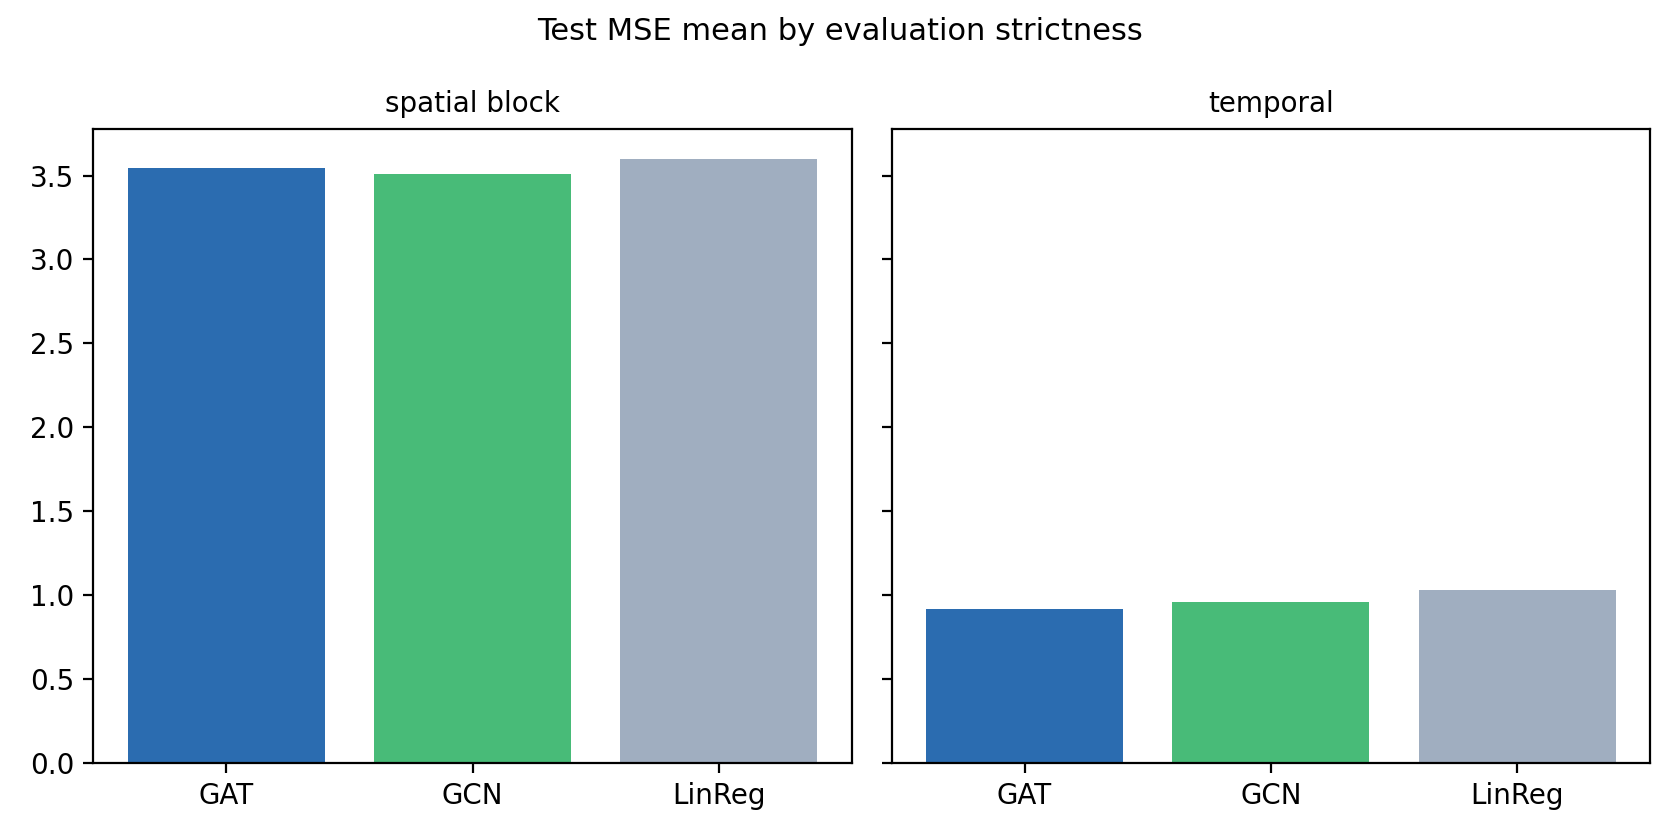

,split,model,mse_mean,mse_std,mae_mean,mae_std,n_runs
0,spatial_block,GAT,3.543588,9.017989,0.293294,0.269430,25
1,spatial_block,GCN,3.510455,9.059153,0.271519,0.250614,25
2,spatial_block,LinReg,3.599838,9.219027,0.330505,0.260600,25
3,temporal,GAT,0.915102,0.032275,0.201838,0.021047,5
4,temporal,GCN,0.958204,0.004555,0.202109,0.008558,5
5,temporal,LinReg,1.028326,0.036371,0.265766,0.060888,5


In [22]:
from IPython.display import Image, display
display(Image("figures/all_splits_summary.png"))
import pandas as pd
pd.read_csv("figures/all_splits_summary.csv")


## Step 7f: Topology Ablation -- Current-Informed vs. Geographic-kNN
Isolates the specific contribution of current-informed edge direction from the general contribution of having graph structure at all. GAT and GCN are each retrained on a geographic-kNN graph with matched per-node degree, spatial block protocol, 5 seeds x 5 folds.

In [ ]:
%%writefile topology_ablation.py
"""
Module 3j: Topology Ablation -- Current-Informed vs. Geographic-kNN

Isolates the specific contribution of current-informed edge DIRECTION from
the general contribution of having graph structure at all. GAT and GCN are
each retrained on two topologies that share identical per-node degree
(max_edges_per_node=5): the current-informed graph, and a geographic-kNN
graph with no reference to current direction. Everything else (features,
architecture, training procedure, spatial-block protocol) is held fixed.

LEAKAGE FIX (same as evaluation_splits.py's build_train_subgraph): training
previously forwarded the FULL graph (train + held-out nodes together) and
only masked the loss to train_idx. Since GATConv/GCNConv aggregate each
node from its graph neighbors, that let held-out node FEATURES leak into
train representations during training, even though the loss itself never
touched held-out labels. Fix: the training loop now forwards only the
node-induced subgraph over train_idx (held-out nodes and any edge touching
one are structurally absent). The full graph is still used at EVAL time
only -- that's inference under a fixed model, not a gradient step, so it
introduces no leakage.

CONFIG-PARITY FIX: this module previously used its own from-scratch
protocol (uniform-random node folds, lr=0.01, epochs=100,
seed=seed*100+fold) that silently diverged from evaluation_splits.py's
spatial_block protocol used for the main Table 4 results. That meant the
"Current-informed" row here (nominally the same graph/model/split as
Table 4's GAT row) was not actually comparable to it. This version imports
the exact split/train routines from evaluation_splits.py instead of
reimplementing them, so both topology rows here are now produced by the
identical protocol used for Table 4, and "Current-informed" should now
agree with Table 4's GAT/GCN numbers (up to run-to-run noise).
"""
import numpy as np
import pandas as pd
import torch
from graph_construction import build_graph
from evaluation_splits import assign_blocks, train_and_eval_gat, train_and_eval_gcn, N_FOLDS, SEEDS

TRAINERS = {"GAT": train_and_eval_gat, "GCN": train_and_eval_gcn}


def _spatial_block_mses(graph, model_cls_name, trainer):
    """
    Same spatial-block-CV protocol as evaluation_splits.run_spatial_block,
    for a single model, so results here are directly comparable to
    Table 4's per-model rows.
    """
    raw_target = graph.x[:, -1:].clone()
    block_ids = assign_blocks(graph.coords)
    rows = []
    for seed in SEEDS:
        rng = np.random.RandomState(seed)
        blocks = np.unique(block_ids)
        rng.shuffle(blocks)
        folds = np.array_split(blocks, N_FOLDS)
        for fold, test_blocks in enumerate(folds):
            test_mask = np.isin(block_ids, test_blocks)
            idx_test = torch.tensor(np.where(test_mask)[0], dtype=torch.long)
            idx_train = torch.tensor(np.where(~test_mask)[0], dtype=torch.long)
            if len(idx_test) == 0 or len(idx_train) == 0:
                continue
            mse, mae = trainer(graph, idx_train, graph, idx_test, raw_target, raw_target, seed)
            rows.append({
                "model": model_cls_name, "seed": seed, "fold": fold,
                "n_train": len(idx_train), "n_test": len(idx_test),
                "mse": mse, "mae": mae,
            })
            print(f"seed={seed} fold={fold} {model_cls_name}: MSE={mse:.4f} MAE={mae:.4f}")
    return rows


def run_topology_ablation():
    rows = []
    for topology in ["current_informed", "geographic_knn"]:
        graph = build_graph("ocean_physics.nc", topology=topology)
        topology_label = "Current-informed" if topology == "current_informed" else "Geographic-kNN"

        for name, trainer in TRAINERS.items():
            print(f"\n=== [{topology_label}] {name} (spatial-block protocol) ===")
            model_rows = _spatial_block_mses(graph, name, trainer)
            for r in model_rows:
                r["topology"] = topology_label
            rows.extend(model_rows)

    df = pd.DataFrame(rows)
    df.to_csv("figures/topology_ablation_results.csv", index=False)

    summary = df.groupby(["topology", "model"]).agg(
        mse_mean=("mse", "mean"), mse_std=("mse", "std"),
        mae_mean=("mae", "mean"), mae_std=("mae", "std"),
        n_runs=("mse", "count"),
    ).reset_index()
    summary.to_csv("figures/topology_ablation_summary.csv", index=False)
    print("\n=== Topology Ablation Summary ===")
    print(summary.to_string(index=False))
    print("\nSaved figures/topology_ablation_results.csv, topology_ablation_summary.csv")


if __name__ == "__main__":
    run_topology_ablation()


In [ ]:
!python topology_ablation.py

## Step 7g: Statistical Significance Testing
Paired Wilcoxon signed-rank tests, bootstrap 95% confidence intervals, and Cohen's d for the model/topology comparisons above, computed directly from per-fold paired MSE values.

In [25]:
%%writefile stats_significance.py
"""
Module 3k: Statistical Significance Testing

Paired Wilcoxon signed-rank tests, bootstrap 95% confidence intervals, and
Cohen's d for the model/topology comparisons most central to this paper's
claims, computed directly from the per-fold paired MSE values in
figures/all_splits_results.csv and figures/topology_ablation_results.csv
(NOT from the aggregated summary files), so fold-level variance is
controlled for rather than compared across independent runs.
"""
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

np.random.seed(0)


def bootstrap_ci(diffs, n_boot=10000, alpha=0.05):
    diffs = np.asarray(diffs)
    n = len(diffs)
    boots = np.empty(n_boot)
    for b in range(n_boot):
        sample = diffs[np.random.randint(0, n, n)]
        boots[b] = sample.mean()
    lo = np.percentile(boots, 100 * alpha / 2)
    hi = np.percentile(boots, 100 * (1 - alpha / 2))
    return lo, hi


def cohens_d(diffs):
    diffs = np.asarray(diffs)
    return float(diffs.mean() / diffs.std(ddof=1))


def paired_report(a, b, name, rows):
    a = np.asarray(a)
    b = np.asarray(b)
    diffs = a - b
    stat, p = wilcoxon(a, b)
    d = cohens_d(diffs)
    lo, hi = bootstrap_ci(diffs)
    print(f"{name}: n={len(a)} mean_diff={diffs.mean():.4f} 95%CI=[{lo:.4f},{hi:.4f}] "
          f"wilcoxon_p={p:.4f} cohend={d:.3f}")
    rows.append({
        "comparison": name, "n": len(a), "mean_diff_mse": diffs.mean(),
        "ci_lo": lo, "ci_hi": hi, "wilcoxon_p": p,
        "significant_05": p < 0.05, "cohens_d": d,
    })


def run_stats_significance():
    rows = []

    splits = pd.read_csv("figures/all_splits_results.csv")

    def get(df, key_cols, split_val, model_val):
        sub = df[(df[key_cols[0]] == split_val) & (df["model"] == model_val)]
        sub = sub.sort_values(["seed", "fold"])
        return sub["mse"].values

    gat_sp = get(splits, ["split"], "spatial_block", "GAT")
    gcn_sp = get(splits, ["split"], "spatial_block", "GCN")
    lin_sp = get(splits, ["split"], "spatial_block", "LinReg")

    print("=== Spatial block (n=25) ===")
    paired_report(gat_sp, gcn_sp, "GAT vs. GCN (spatial block)", rows)
    paired_report(gat_sp, lin_sp, "GAT vs. LinReg (spatial block)", rows)

    try:
        topo = pd.read_csv("figures/topology_ablation_results.csv")

        def get2(topology_val, model_val):
            sub = topo[(topo["topology"] == topology_val) & (topo["model"] == model_val)]
            sub = sub.sort_values(["seed", "fold"])
            return sub["mse"].values

        gat_c = get2("Current-informed", "GAT")
        gcn_c = get2("Current-informed", "GCN")
        gat_k = get2("Geographic-kNN", "GAT")
        gcn_k = get2("Geographic-kNN", "GCN")

        print("\n=== Topology ablation (n=25 each) ===")
        paired_report(gat_c, gcn_c, "GAT vs. GCN (current-informed)", rows)
        paired_report(gat_c, gat_k, "GAT: current-informed vs. geographic-kNN", rows)
        paired_report(gcn_c, gcn_k, "GCN: current-informed vs. geographic-kNN", rows)
    except FileNotFoundError:
        print("\ntopology_ablation_results.csv not found -- run topology_ablation.py first "
              "to include those comparisons.")

    out = pd.DataFrame(rows)
    out.to_csv("figures/stats_pairwise.csv", index=False)
    print("\nSaved figures/stats_pairwise.csv")
    return out


if __name__ == "__main__":
    run_stats_significance()


Writing stats_significance.py


In [26]:
!python stats_significance.py

=== Spatial block (n=25) ===
GAT vs. GCN (spatial block): n=25 mean_diff=0.0331 95%CI=[-0.0132,0.0939] wilcoxon_p=0.9368 cohend=0.232
GAT vs. LinReg (spatial block): n=25 mean_diff=-0.0562 95%CI=[-0.1580,0.0467] wilcoxon_p=0.0755 cohend=-0.211

=== Topology ablation (n=25 each) ===
GAT vs. GCN (current-informed): n=25 mean_diff=-0.1998 95%CI=[-0.3358,-0.0654] wilcoxon_p=0.0125 cohend=-0.566
GAT: current-informed vs. geographic-kNN: n=25 mean_diff=0.0367 95%CI=[-0.0382,0.1045] wilcoxon_p=0.1199 cohend=0.198
GCN: current-informed vs. geographic-kNN: n=25 mean_diff=-0.0001 95%CI=[-0.0267,0.0284] wilcoxon_p=0.6338 cohend=-0.002

Saved figures/stats_pairwise.csv


## Step 7h: Hyperparameter Sensitivity Analysis
Checks whether results are an artifact of the untuned default graph-construction hyperparameters (angular tolerance, max_edges_per_node, drift threshold) by sweeping each in turn under the spatial block protocol.

In [ ]:
%%writefile hyperparameter_sensitivity.py
"""
Module 3l: Hyperparameter Sensitivity Analysis

Checks whether the reported results are an artifact of a fortunate default
setting for the three graph-construction hyperparameters (angular
tolerance, max_edges_per_node, drift threshold), all previously described
as empirically chosen but untuned. GAT is retrained across a small grid of
alternative values for each hyperparameter in turn, holding the other two
at their default, under the spatial block protocol (5 seeds x 5 folds).

LEAKAGE FIX (same as evaluation_splits.py's build_train_subgraph): training
previously forwarded the FULL graph (train + held-out nodes together) and
only masked the loss to train_idx, letting held-out node FEATURES leak into
train representations via GATConv's neighbor aggregation. Fix: the training
loop now forwards only the node-induced subgraph over train_idx. The full
graph is still used at EVAL time only (inference under a fixed model).

CONFIG-PARITY FIX: this module previously used its own from-scratch
protocol (uniform-random node folds, lr=0.01, epochs=100, seed=seed*100+fold)
that silently diverged from evaluation_splits.py's spatial_block protocol
used for the main GAT result in Table 4 (block-CV folds from assign_blocks,
lr=0.005, epochs=min(EPOCHS_GAT, 120), seed=seed). That mismatch is what
made the "default" row of this table (MSE ~10.072) incomparable to Table 4's
GAT MSE (3.544), even though both were nominally the same default
hyperparameters. This version imports the exact split/train routine from
evaluation_splits.py instead of reimplementing it, so the default row here
is now produced by the identical protocol used for Table 4, and the two
numbers should now agree (up to run-to-run noise).
"""
import numpy as np
import pandas as pd
import torch
from graph_construction import build_graph
from evaluation_splits import assign_blocks, train_and_eval_gat, N_FOLDS, SEEDS

DEFAULT_ANGLE = 45.0
DEFAULT_MAX_EDGES = 5
DEFAULT_DRIFT = 0.02

SWEEP = {
    "angle_tolerance_deg": [15.0, 30.0, 45.0, 60.0, 90.0],
    "max_edges_per_node": [2, 3, 5, 8, 12],
    "drift_threshold": [0.0, 0.01, 0.02, 0.05, 0.1],
}


def _spatial_block_gat_mses(graph):
    """
    Same spatial-block-CV protocol as evaluation_splits.run_spatial_block,
    restricted to the GAT model, so results here are directly comparable
    to Table 4's GAT row.
    """
    raw_target = graph.x[:, -1:].clone()
    block_ids = assign_blocks(graph.coords)
    mses = []
    for seed in SEEDS:
        rng = np.random.RandomState(seed)
        blocks = np.unique(block_ids)
        rng.shuffle(blocks)
        folds = np.array_split(blocks, N_FOLDS)
        for test_blocks in folds:
            test_mask = np.isin(block_ids, test_blocks)
            idx_test = torch.tensor(np.where(test_mask)[0], dtype=torch.long)
            idx_train = torch.tensor(np.where(~test_mask)[0], dtype=torch.long)
            if len(idx_test) == 0 or len(idx_train) == 0:
                continue
            mse, _ = train_and_eval_gat(
                graph, idx_train, graph, idx_test, raw_target, raw_target, seed
            )
            mses.append(mse)
    return np.array(mses)


def run_hyperparameter_sensitivity():
    rows = []
    for hyperparam, values in SWEEP.items():
        for value in values:
            kwargs = dict(angle_tolerance_deg=DEFAULT_ANGLE,
                           max_edges_per_node=DEFAULT_MAX_EDGES,
                           drift_threshold=DEFAULT_DRIFT)
            kwargs[hyperparam] = value
            is_default = (value == {"angle_tolerance_deg": DEFAULT_ANGLE,
                                     "max_edges_per_node": DEFAULT_MAX_EDGES,
                                     "drift_threshold": DEFAULT_DRIFT}[hyperparam])

            graph = build_graph("ocean_physics.nc", **kwargs)
            mses = _spatial_block_gat_mses(graph)
            rows.append({
                "hyperparam": hyperparam, "value": value, "is_default": is_default,
                "mse_mean": mses.mean(), "mse_std": mses.std(),
                "n_edges": graph.num_edges,
            })
            print(f"{hyperparam}={value} (default={is_default}): "
                  f"MSE={mses.mean():.4f}+-{mses.std():.4f} n_edges={graph.num_edges}")

    df = pd.DataFrame(rows)
    df.to_csv("figures/hyperparam_sensitivity_results.csv", index=False)
    print("\nSaved figures/hyperparam_sensitivity_results.csv")
    return df


if __name__ == "__main__":
    run_hyperparameter_sensitivity()


In [ ]:
!python hyperparameter_sensitivity.py

## Step 7i: Land-Cell Handling Strategy Comparison
Compares the default zero-fill land-cell strategy against dropping land cells entirely and against zero-fill plus an explicit binary validity-mask feature.

In [ ]:
%%writefile land_handling.py
"""
Module 3m: Land-Cell Handling Strategy Comparison

Tests whether zero-filling land cells (the default) shapes results, by
comparing it against dropping land cells entirely and against zero-fill
plus an explicit binary validity-mask feature. GAT and GCN are retrained
under all three strategies, spatial block protocol, 5 seeds x 5 folds each.

LEAKAGE FIX (same as evaluation_splits.py's build_train_subgraph): training
previously forwarded the FULL graph (train + held-out nodes together) and
only masked the loss to train_idx, letting held-out node FEATURES leak into
train representations via GATConv/GCNConv's neighbor aggregation. Fix: the
training loop now forwards only the node-induced subgraph over train_idx.
The full graph is still used at EVAL time only (inference under a fixed
model).

CONFIG-PARITY FIX: this module previously used its own from-scratch
protocol (uniform-random node folds, lr=0.01, epochs=100,
seed=seed*100+fold) that silently diverged from evaluation_splits.py's
spatial_block protocol used for the main Table 4 results -- the same
class of mismatch found and fixed in topology_ablation.py and
hyperparameter_sensitivity.py. That meant the "zero-fill (default)" row
here (nominally the same graph/model/split as Table 4's GAT/GCN rows) was
not actually comparable to Table 4. This version imports the exact
split/train routines from evaluation_splits.py instead of reimplementing
them, so all three strategy rows here are now produced by the identical
protocol used for Table 4, and "zero-fill (default)" should now agree
with Table 4's GAT/GCN numbers (up to run-to-run noise).
"""
import numpy as np
import pandas as pd
import torch
from graph_construction import build_graph
from evaluation_splits import assign_blocks, train_and_eval_gat, train_and_eval_gcn, N_FOLDS, SEEDS

STRATEGIES = ["zero_fill", "remove", "valid_mask"]
TRAINERS = {"GAT": train_and_eval_gat, "GCN": train_and_eval_gcn}


def _spatial_block_mses(graph, model_cls_name, trainer):
    """
    Same spatial-block-CV protocol as evaluation_splits.run_spatial_block,
    for a single model, so results here are directly comparable to
    Table 4's per-model rows.
    """
    raw_target = graph.x[:, -1:].clone()
    block_ids = assign_blocks(graph.coords)
    rows = []
    for seed in SEEDS:
        rng = np.random.RandomState(seed)
        blocks = np.unique(block_ids)
        rng.shuffle(blocks)
        folds = np.array_split(blocks, N_FOLDS)
        for fold, test_blocks in enumerate(folds):
            test_mask = np.isin(block_ids, test_blocks)
            idx_test = torch.tensor(np.where(test_mask)[0], dtype=torch.long)
            idx_train = torch.tensor(np.where(~test_mask)[0], dtype=torch.long)
            if len(idx_test) == 0 or len(idx_train) == 0:
                continue
            mse, mae = trainer(graph, idx_train, graph, idx_test, raw_target, raw_target, seed)
            rows.append({
                "model": model_cls_name, "seed": seed, "fold": fold,
                "mse": mse, "mae": mae,
            })
            print(f"seed={seed} fold={fold} {model_cls_name}: MSE={mse:.4f} MAE={mae:.4f}")
    return rows


def run_land_handling_comparison():
    rows = []
    for strategy in STRATEGIES:
        graph = build_graph("ocean_physics.nc", land_handling=strategy)
        for name, trainer in TRAINERS.items():
            print(f"\n=== [{strategy}] {name} (spatial-block protocol) ===")
            model_rows = _spatial_block_mses(graph, name, trainer)
            for r in model_rows:
                r["strategy"] = strategy
            rows.extend(model_rows)

    df = pd.DataFrame(rows)
    df.to_csv("figures/land_handling_results.csv", index=False)

    summary = df.groupby(["strategy", "model"]).agg(
        mse_mean=("mse", "mean"), mae_mean=("mae", "mean"), n_runs=("mse", "count")
    ).reset_index()
    print("\n=== Land-Handling Summary ===")
    print(summary.to_string(index=False))
    print("\nSaved figures/land_handling_results.csv")
    return df


if __name__ == "__main__":
    run_land_handling_comparison()


In [ ]:
!python land_handling.py

## Step 7e: Extra visualizations (heatmaps, spatial maps, attention map)


In [31]:
%%writefile extra_visualizations.py
"""
Module 3i: Extra Visualizations for the Paper
Generates additional publication-ready figures beyond results_plots.py and
evaluation_splits.py's summary bar chart:

  1. mse_heatmap.png        - split x model heatmap of mean MSE
  2. attention_distribution.png - histogram of GAT attention weights
  3. spatial_prediction_map.png - lat/lon scatter, node color = predicted
                                   biodiversity score (GAT), from the
                                   spatial-only graph
  4. spatial_error_map.png  - lat/lon scatter, node color = |pred - true|
  5. attention_map.png      - lat/lon scatter, node color = mean incoming
                              attention weight per node (which regions the
                              model treats as most influential)

Run AFTER evaluation_splits.py (needs figures/all_splits_summary.csv) and
after gat_model.py / explainability.py have been run at least once (needs
marina_gat.pt, and reuses graph_construction.py directly).

Usage:
    python extra_visualizations.py
Produces (saved to ./figures/):
    mse_heatmap.png
    attention_distribution.png
    spatial_prediction_map.png
    spatial_error_map.png
    attention_map.png
"""
import os
import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

from graph_construction import build_graph, FEATURE_COLUMNS
from gat_model import MarinaGAT

os.makedirs("figures", exist_ok=True)
sns.set_style("whitegrid")

MODEL_ORDER = ["GAT", "GCN", "LinReg"]
SPLIT_ORDER = ["temporal", "spatial_block"]


# ---------- 1 & 2: heatmaps from all_splits_summary.csv ----------

def plot_metric_heatmap(summary_csv="figures/all_splits_summary.csv"):
    df = pd.read_csv(summary_csv)

    mse_pivot = df.pivot(index="split", columns="model", values="mse_mean").reindex(
        index=SPLIT_ORDER, columns=MODEL_ORDER)

    fig, ax = plt.subplots(figsize=(6, 4.2))
    sns.heatmap(mse_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r", ax=ax,
                cbar_kws={"label": "Mean MSE (lower = better)"}, linewidths=0.5)
    ax.set_title("Mean Test MSE by Split and Model")
    ax.set_xlabel(""); ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig("figures/mse_heatmap.png", dpi=200)
    plt.close(fig)

    print("Saved figures/mse_heatmap.png")


# ---------- helpers: load trained GAT + spatial graph ----------

def load_gat_and_graph(weights_path="marina_gat.pt", physics_nc="ocean_physics.nc"):
    graph = build_graph(physics_nc)
    model = MarinaGAT(in_channels=graph.x.shape[1] - 1)
    state = torch.load(weights_path, map_location="cpu")
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        preds, (attn1, attn2) = model(graph.x, graph.edge_index, return_attention=True)
    return graph, model, preds, attn1


# ---------- 3: attention weight distribution ----------

def plot_attention_distribution(attn1):
    edge_index_out, alpha = attn1
    alpha_mean = alpha.mean(dim=1).numpy()
    src, dst = edge_index_out[0].numpy(), edge_index_out[1].numpy()
    non_self = src != dst
    weights = alpha_mean[non_self]

    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.hist(weights, bins=40, color="#2b6cb0", edgecolor="white")
    ax.axvline(np.median(weights), color="#e53e3e", linestyle="--",
               label=f"median = {np.median(weights):.3f}")
    ax.set_xlabel("Attention weight (layer 1, head-averaged, excl. self-loops)")
    ax.set_ylabel("Edge count")
    ax.set_title("Distribution of GAT Attention Weights over Current-Informed Edges")
    ax.legend()
    fig.tight_layout()
    fig.savefig("figures/attention_distribution.png", dpi=200)
    plt.close(fig)
    print("Saved figures/attention_distribution.png")


# ---------- 4 & 5: spatial prediction / error maps ----------

def plot_spatial_prediction_and_error(graph, preds):
    coords = graph.coords.reset_index(drop=True)
    pred = preds.squeeze().numpy()
    raw_target = graph.x[:, -1:].squeeze().numpy()
    target_norm = (raw_target - raw_target.mean()) / (raw_target.std() + 1e-6)
    valid = graph.x[:, 0].numpy() != 0.0  # drop zeroed land/missing cells

    lat, lon = coords["lat"].values, coords["lon"].values

    fig, ax = plt.subplots(figsize=(6.5, 6))
    sc = ax.scatter(lon[valid], lat[valid], c=pred[valid], cmap="viridis", s=18)
    fig.colorbar(sc, ax=ax, label="Predicted biodiversity score (normalized)")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title("GAT Predicted Biodiversity Score by Location")
    fig.tight_layout()
    fig.savefig("figures/spatial_prediction_map.png", dpi=200)
    plt.close(fig)

    err = np.abs(pred - target_norm)
    fig, ax = plt.subplots(figsize=(6.5, 6))
    sc = ax.scatter(lon[valid], lat[valid], c=err[valid], cmap="Reds", s=18)
    fig.colorbar(sc, ax=ax, label="|Predicted - True| (normalized)")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title("GAT Absolute Prediction Error by Location")
    fig.tight_layout()
    fig.savefig("figures/spatial_error_map.png", dpi=200)
    plt.close(fig)

    print("Saved figures/spatial_prediction_map.png, figures/spatial_error_map.png")


# ---------- 6: spatial attention map (mean incoming attention per node) ----------

def plot_attention_map(graph, attn1):
    edge_index_out, alpha = attn1
    alpha_mean = alpha.mean(dim=1).numpy()
    dst = edge_index_out[1].numpy()
    src = edge_index_out[0].numpy()
    non_self = src != dst

    n = graph.num_nodes
    incoming = np.zeros(n)
    counts = np.zeros(n)
    for d, w in zip(dst[non_self], alpha_mean[non_self]):
        incoming[d] += w
        counts[d] += 1
    counts[counts == 0] = 1
    incoming_mean = incoming / counts

    coords = graph.coords.reset_index(drop=True)
    valid = graph.x[:, 0].numpy() != 0.0
    lat, lon = coords["lat"].values, coords["lon"].values

    fig, ax = plt.subplots(figsize=(6.5, 6))
    sc = ax.scatter(lon[valid], lat[valid], c=incoming_mean[valid], cmap="magma", s=18)
    fig.colorbar(sc, ax=ax, label="Mean incoming attention weight")
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.set_title("Spatial Distribution of GAT Attention (Explainability Map)")
    fig.tight_layout()
    fig.savefig("figures/attention_map.png", dpi=200)
    plt.close(fig)
    print("Saved figures/attention_map.png")


def run_all():
    print("=== 1. Heatmap from evaluation_splits.py summary ===")
    if os.path.exists("figures/all_splits_summary.csv"):
        plot_metric_heatmap()
    else:
        print("figures/all_splits_summary.csv not found -- run evaluation_splits.py first. Skipping heatmap.")

    print("\n=== Loading trained GAT + spatial graph for attention/map figures ===")
    try:
        graph, model, preds, attn1 = load_gat_and_graph()
    except FileNotFoundError as e:
        print(f"Skipping attention/map figures -- missing file: {e}")
        return

    print("\n=== 2. Attention weight distribution ===")
    plot_attention_distribution(attn1)

    print("\n=== 3-4. Spatial prediction and error maps ===")
    plot_spatial_prediction_and_error(graph, preds)

    print("\n=== 5. Spatial attention map ===")
    plot_attention_map(graph, attn1)

    print("\nAll extra figures saved to ./figures/")


if __name__ == "__main__":
    run_all()


Writing extra_visualizations.py


In [32]:
!pip install seaborn --quiet
!python extra_visualizations.py


=== 1. Heatmap from evaluation_splits.py summary ===
Saved figures/mse_heatmap.png

=== Loading trained GAT + spatial graph for attention/map figures ===
Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill

=== 2. Attention weight distribution ===
Saved figures/attention_distribution.png

=== 3-4. Spatial prediction and error maps ===
Saved figures/spatial_prediction_map.png, figures/spatial_error_map.png

=== 5. Spatial attention map ===
Saved figures/attention_map.png

All extra figures saved to ./figures/


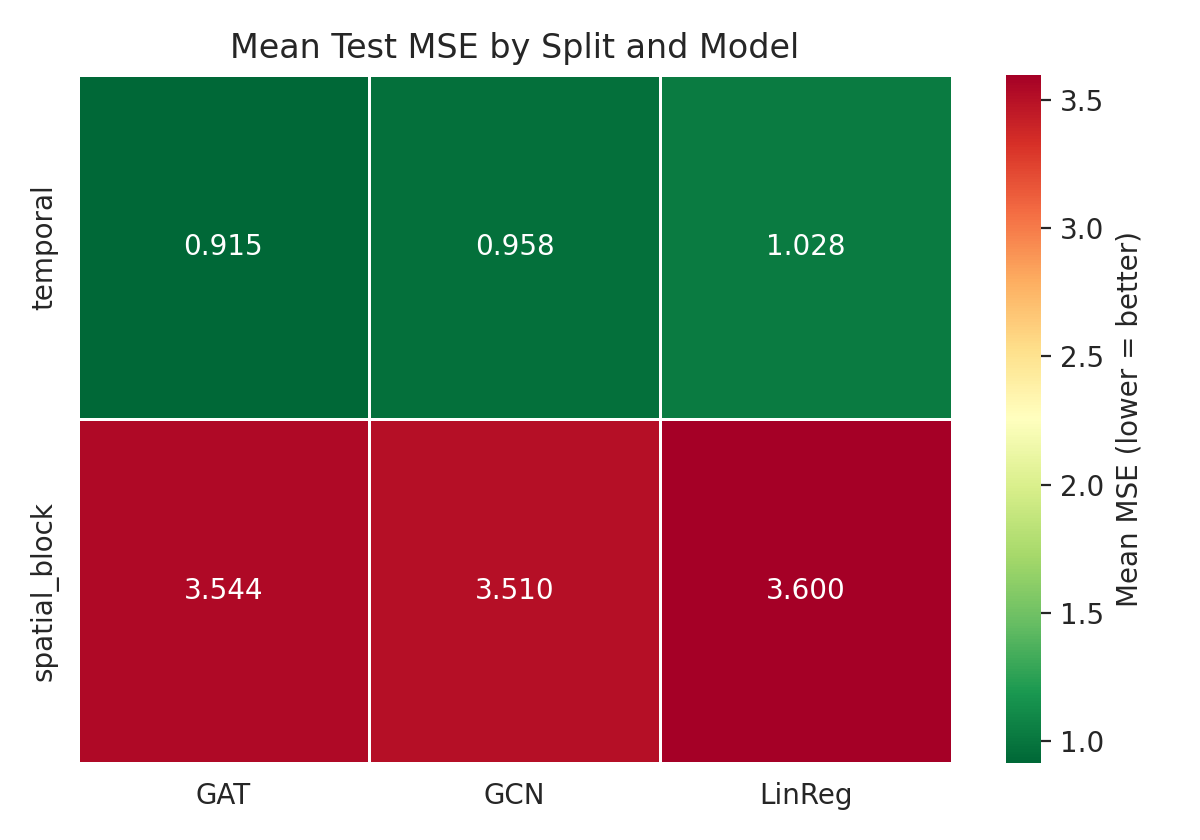

FileNotFoundError: No such file or directory: 'figures/regularization_before_after.png'

FileNotFoundError: No such file or directory: 'figures/regularization_before_after.png'

<IPython.core.display.Image object>

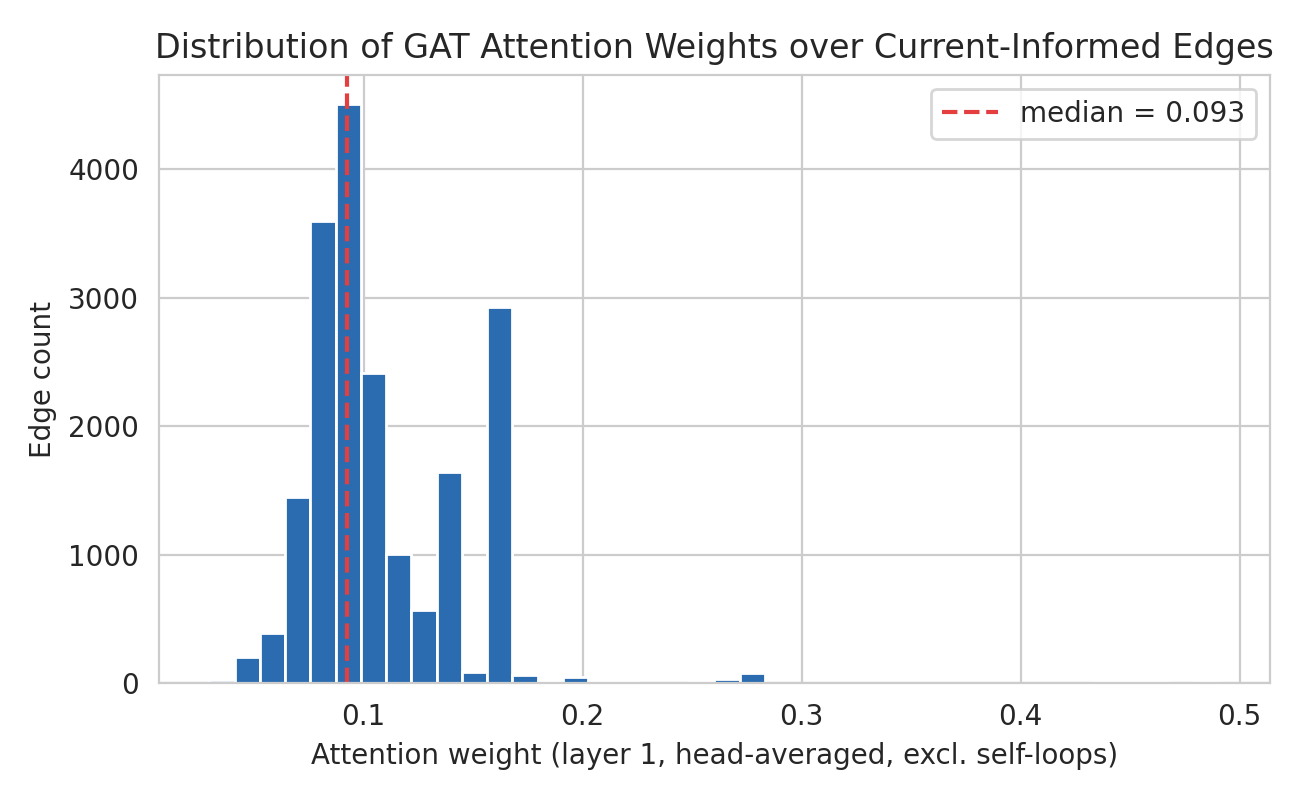

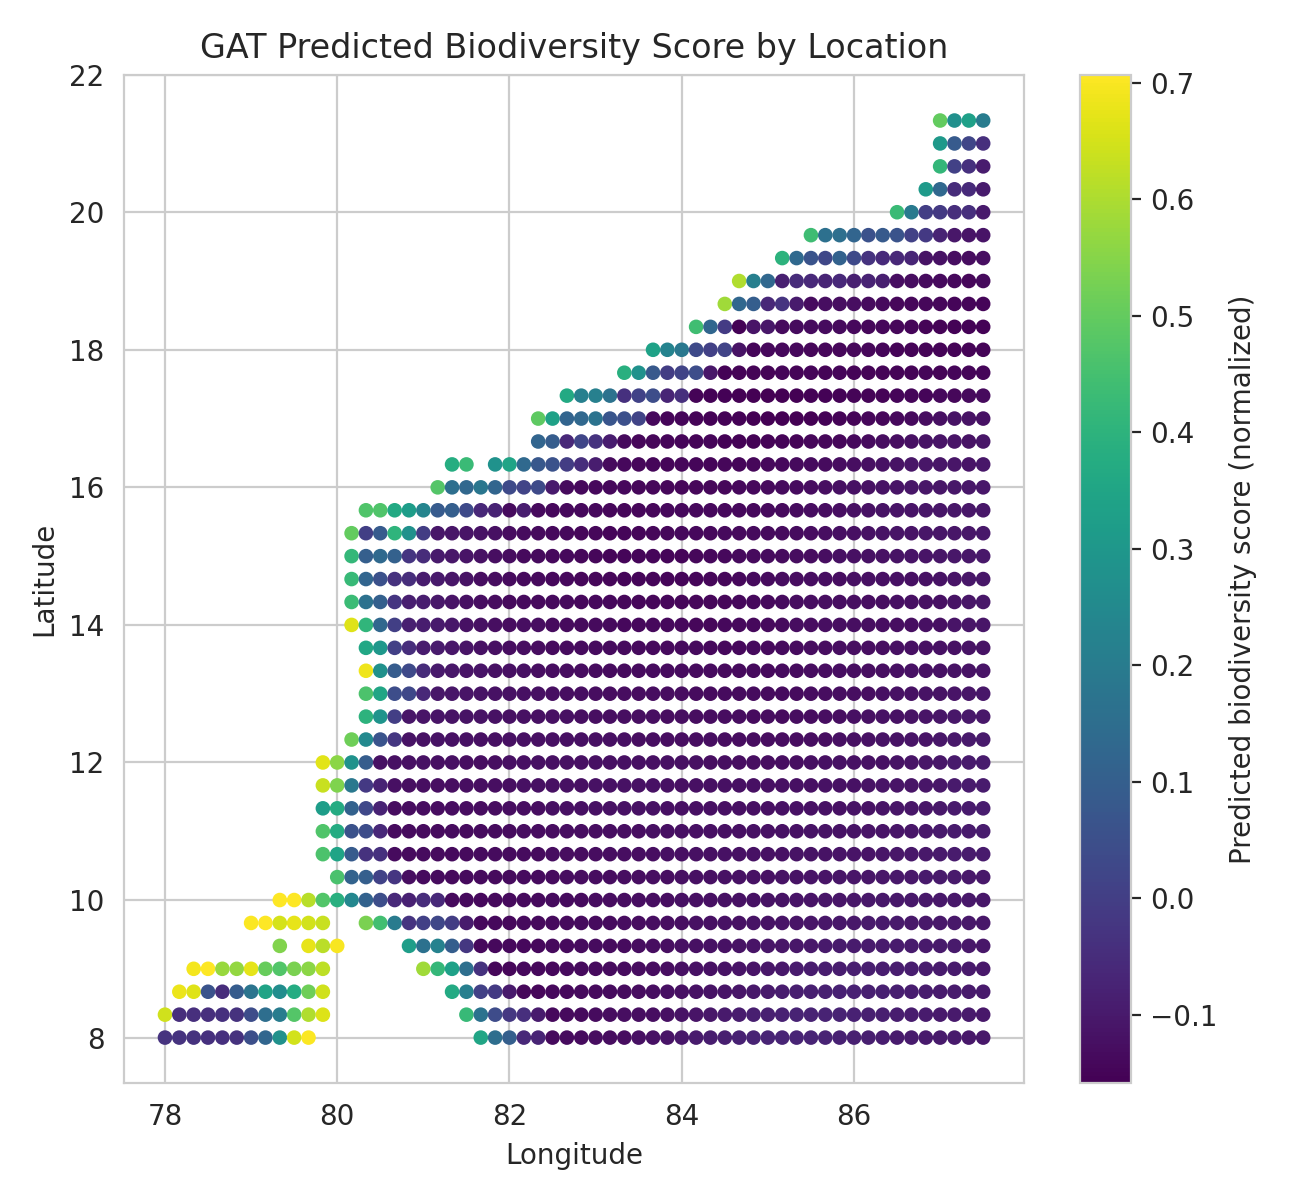

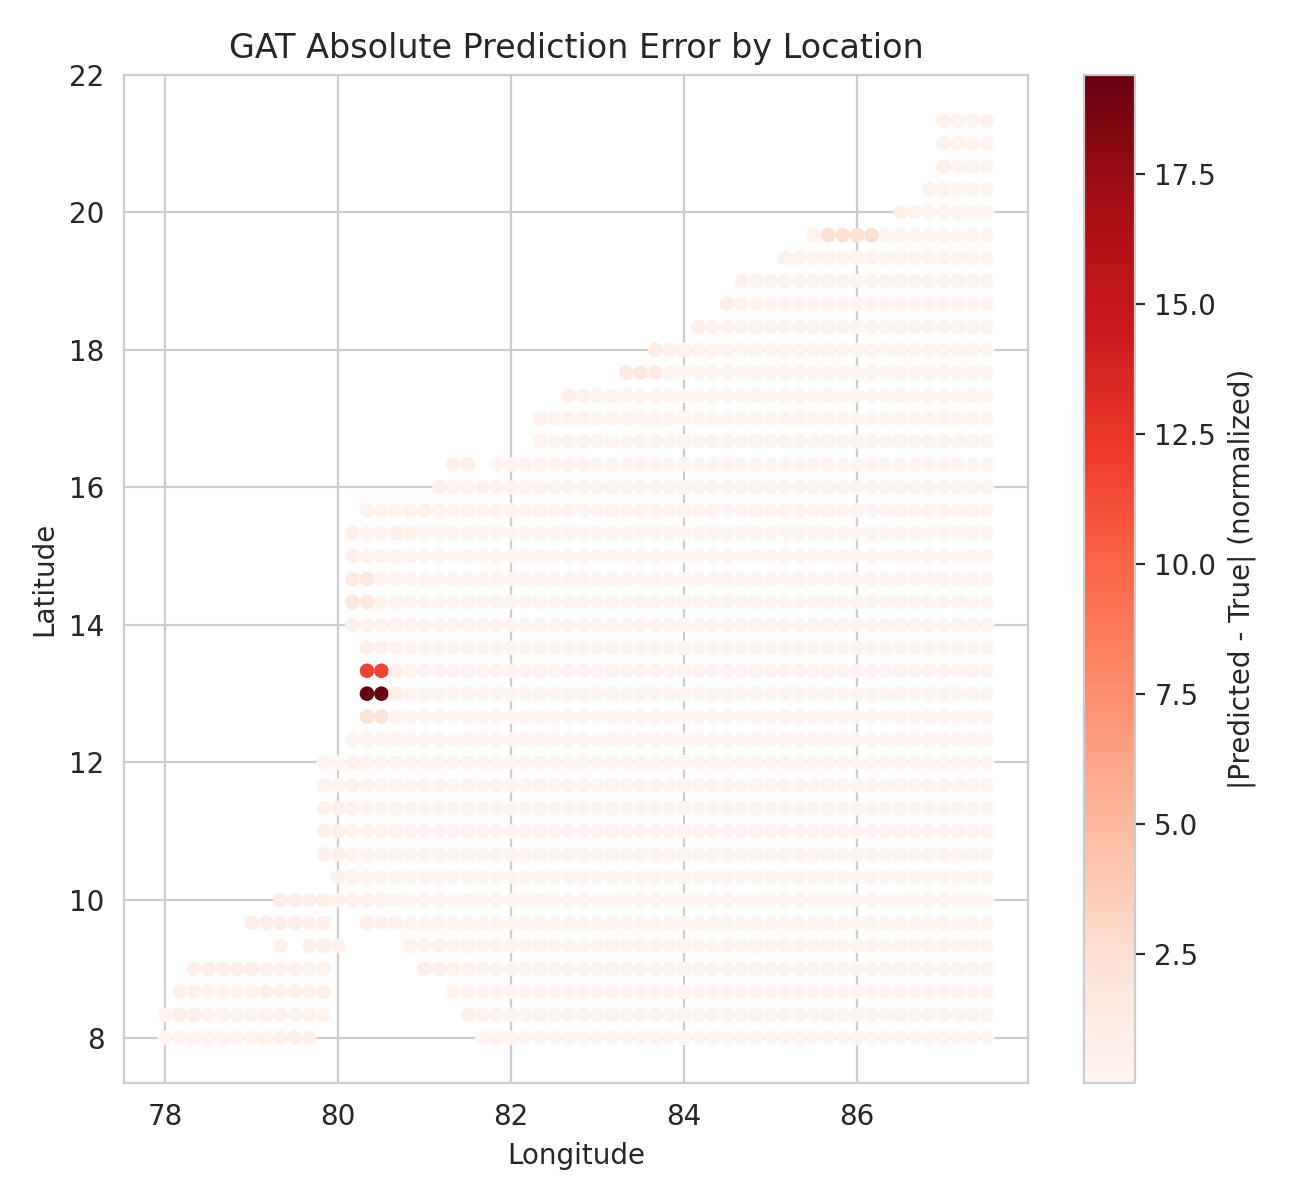

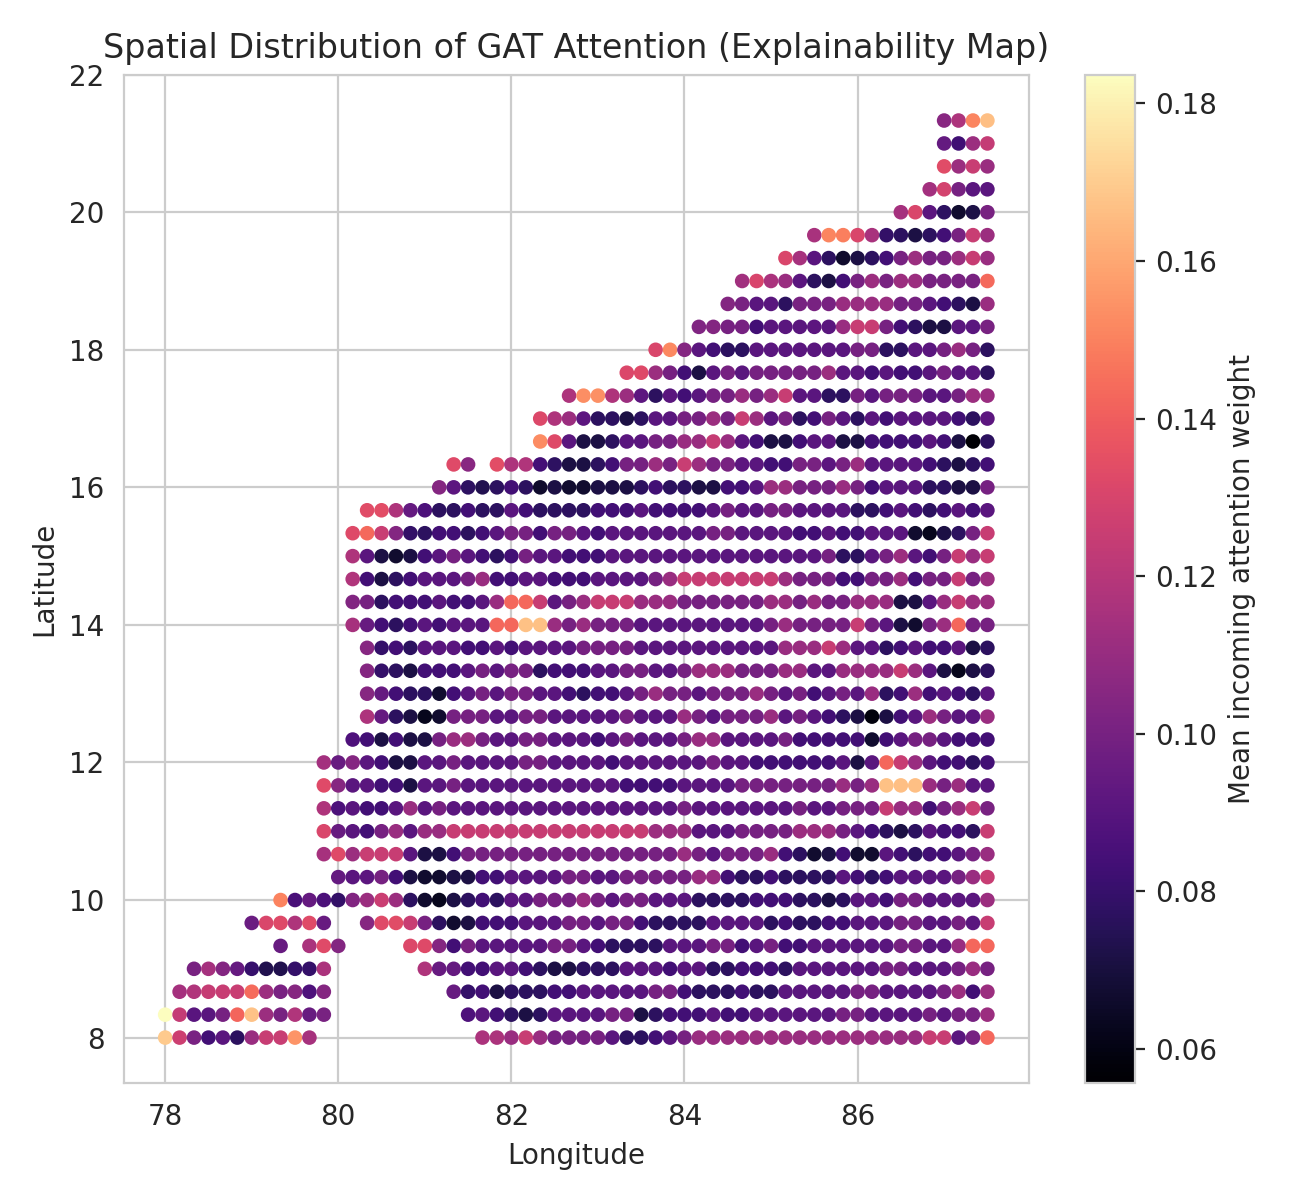

In [33]:
from IPython.display import Image, display
for f in ["mse_heatmap.png", "regularization_before_after.png",
          "attention_distribution.png", "spatial_prediction_map.png",
          "spatial_error_map.png", "attention_map.png"]:
    display(Image(f"figures/{f}"))


## Step 8: Explainability

In [34]:
%%writefile explainability.py
"""
Module 4: Explainability
Extracts GAT attention weights and links them to real oceanographic drivers.
This is the paper's key XAI contribution: attention isn't just a number,
it's tied to WHY a region matters (strong current, upwelling-like temp/salinity
gradient, etc.)

Updated to use the time-aggregated feature columns from graph_construction.py
(temp_mean, salinity_mean, u_mean, v_mean, ...) instead of the old single-
snapshot columns (temp, salinity, u, v).
"""
import torch
import pandas as pd
import numpy as np
from graph_construction import build_graph, FEATURE_COLUMNS
from gat_model import MarinaGAT


def extract_attention(model, graph):
    """
    Run inference and pull out attention weights from the first GAT layer
    (most interpretable - shows raw region-to-region importance).
    """
    model.eval()
    with torch.no_grad():
        preds, (attn1, attn2) = model(graph.x, graph.edge_index, return_attention=True)

    edge_index_out, alpha = attn1  # alpha shape: [num_edges, num_heads]
    alpha_mean = alpha.mean(dim=1)  # average across attention heads

    src = edge_index_out[0].numpy()
    dst = edge_index_out[1].numpy()

    return pd.DataFrame({
        "source_node": src,
        "target_node": dst,
        "attention_weight": alpha_mean.numpy(),
    }), preds


def explain_top_edges(attn_df, graph, node_df, top_k=10):
    """
    For the highest-attention edges, explain WHY in oceanographic terms:
    - strong mean current magnitude -> active drift/transport pathway
    - temperature/salinity gradient -> possible upwelling or mixing zone
    - high temp_std/u_std/v_std -> a volatile node (unstable conditions),
      worth flagging separately since it changes how much to trust the
      time-mean edge direction there
    """
    # Remove self-loops (GATConv auto-adds these internally; they always get
    # inflated attention ~1.0 and aren't meaningful region-to-region connections)
    attn_df = attn_df[attn_df["source_node"] != attn_df["target_node"]].reset_index(drop=True)

    # Remove edges touching zeroed-out land/missing-data cells (temp_mean=0 is
    # not a real ocean reading here - it's our NaN placeholder from
    # graph_construction.py)
    valid_nodes = node_df[node_df["temp_mean"] != 0.0].index
    attn_df = attn_df[
        attn_df["source_node"].isin(valid_nodes) & attn_df["target_node"].isin(valid_nodes)
    ].reset_index(drop=True)

    top_edges = attn_df.sort_values("attention_weight", ascending=False).head(top_k).copy()

    explanations = []
    for _, row in top_edges.iterrows():
        i, j = int(row.source_node), int(row.target_node)

        temp_i, sal_i, u_i, v_i, temp_std_i = node_df.iloc[i][
            ["temp_mean", "salinity_mean", "u_mean", "v_mean", "temp_std"]
        ]
        temp_j, sal_j = node_df.iloc[j][["temp_mean", "salinity_mean"]]

        current_mag = np.sqrt(u_i**2 + v_i**2)
        temp_gradient = abs(temp_i - temp_j)
        sal_gradient = abs(sal_i - sal_j)

        reasons = []
        if current_mag > 0.1:
            reasons.append(f"strong mean current ({current_mag:.2f} m/s) driving connectivity")
        if temp_gradient > 0.5:
            reasons.append(f"temperature gradient ({temp_gradient:.2f}\u00b0C) suggesting upwelling/mixing")
        if sal_gradient > 0.3:
            reasons.append(f"salinity gradient ({sal_gradient:.2f} PSU)")
        if temp_std_i > 0.5:
            reasons.append(f"source node is thermally volatile over the window (std={temp_std_i:.2f}\u00b0C) "
                            f"-- treat this edge's direction as less stable")
        if not reasons:
            reasons.append("weak but consistent drift pathway")

        lat_i, lon_i = graph.coords.iloc[i][["lat", "lon"]]
        lat_j, lon_j = graph.coords.iloc[j][["lat", "lon"]]

        explanations.append({
            "region": f"({lat_i:.3f},{lon_i:.3f}) -> ({lat_j:.3f},{lon_j:.3f})",
            "attention_weight": round(row.attention_weight, 4),
            "explanation": "; ".join(reasons),
        })

    return pd.DataFrame(explanations)


if __name__ == "__main__":
    graph = build_graph("ocean_physics.nc")
    model = MarinaGAT(in_channels=graph.x.shape[1] - 1)  # matches gat_model.py training convention
    model.load_state_dict(torch.load("marina_gat.pt"))

    node_df = pd.DataFrame(graph.x.numpy(), columns=FEATURE_COLUMNS)

    attn_df, preds = extract_attention(model, graph)
    print(f"Extracted attention for {len(attn_df)} edges\n")

    explained = explain_top_edges(attn_df, graph, node_df, top_k=10)
    print("Top 10 most influential region-to-region connections:\n")
    print(explained.to_string(index=False))

    explained.to_csv("explainability_report.csv", index=False)
    print("\nSaved to explainability_report.csv")


Writing explainability.py


In [35]:
!python explainability.py

Graph built: 2378 nodes, 19190 current_informed edges, 11 input features/node (+ species_richness target); land_handling=zero_fill
Extracted attention for 21568 edges

Top 10 most influential region-to-region connections:

                            region  attention_weight                                                                                                                                                                                     explanation
  (8.333,78.333) -> (8.000,78.000)            0.1873                                                                                  strong mean current (0.16 m/s) driving connectivity; temperature gradient (2.42°C) suggesting upwelling/mixing
  (8.333,78.500) -> (8.000,78.000)            0.1790                                                                                  strong mean current (0.48 m/s) driving connectivity; temperature gradient (2.43°C) suggesting upwelling/mixing
(21.333,87.000) -> (21.333,87.500)        

## Step 9: Write dashboard app

In [36]:
!pip install nest_asyncio

In [37]:
%%writefile dashboard.py
"""
Module 5+6: Live Dashboard with Review-Flag Logic

FastAPI backend serving:
  - GAT predictions per region
  - Explainability (attention) overlay
  - Automatic review flag when a region's predicted score falls in the
    lowest percentile of this run's own distribution

Run with: uvicorn dashboard:app --reload
Then open the printed local URL, or in Colab use ngrok/pyngrok to expose it.

Updated to use the time-aggregated feature columns from graph_construction.py
(temp_mean, ... ) instead of the old single-snapshot columns (temp, ...).
"""

import torch
import numpy as np
import pandas as pd
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from graph_construction import build_graph, FEATURE_COLUMNS
from gat_model import MarinaGAT
from explainability import extract_attention, explain_top_edges

app = FastAPI(
    title="Marina Biodiversity Monitor - India East Coast"
)

# ---- Config ----
REVIEW_PERCENTILE = 20

# ---- Load graph + model once at startup ----
graph = build_graph("ocean_physics.nc")

model = MarinaGAT(
    in_channels=graph.x.shape[1] - 1
)

model.load_state_dict(
    torch.load("marina_gat.pt")
)

model.eval()

node_df = pd.DataFrame(
    graph.x.numpy(),
    columns=FEATURE_COLUMNS
)


def run_prediction_and_flags():
    with torch.no_grad():
        preds, _ = model(
            graph.x,
            graph.edge_index,
            return_attention=True
        )

    preds = preds.squeeze().numpy()

    results = graph.coords.copy()
    results["predicted_score"] = preds
    results["temp_mean"] = node_df["temp_mean"].values

    # Drop land / no-data cells
    results = results[
        results["temp_mean"] != 0.0
    ].reset_index(drop=True)

    # Flag the lowest-scoring regions
    cutoff = np.percentile(
        results["predicted_score"],
        REVIEW_PERCENTILE
    )

    results["flagged_for_review"] = (
        results["predicted_score"] <= cutoff
    )

    return results


@app.get("/api/predictions")
def get_predictions():
    """Returns per-region prediction and review flag."""

    results = run_prediction_and_flags()

    return {
        "records": results.to_dict(
            orient="records"
        )
    }


@app.get("/api/flagged-for-review")
def get_flagged_for_review():
    """Returns regions in the bottom REVIEW_PERCENTILE
    of predicted scores.
    """

    results = run_prediction_and_flags()

    flagged = results[
        results["flagged_for_review"]
    ]

    return {
        "num_zones_flagged": len(flagged),
        "zones": flagged.to_dict(
            orient="records"
        ),
    }


@app.get("/api/explainability")
def get_explainability(top_k: int = 10):
    """Returns top attention-weighted region connections."""

    attn_df, _ = extract_attention(
        model,
        graph
    )

    explained = explain_top_edges(
        attn_df,
        graph,
        node_df,
        top_k=top_k
    )

    return explained.to_dict(
        orient="records"
    )


@app.get("/", response_class=HTMLResponse)
def dashboard():
    """Dashboard map."""

    results = run_prediction_and_flags()

    markers_js = ""

    for _, row in results.iterrows():

        color = (
            "red"
            if row["flagged_for_review"]
            else "green"
        )

        markers_js += (
            f'L.circleMarker('
            f'[{row.lat}, {row.lon}], '
            f'{{radius:8, color:"{color}", fillOpacity:0.7}}'
            f')'
            f'.addTo(map)'
            f'.bindPopup('
            f'"Score: {row.predicted_score:.3f}<br>'
            f'Flagged for review: '
            f'{row.flagged_for_review}"'
            f');\n'
        )

    center_lat = results["lat"].mean()
    center_lon = results["lon"].mean()

    html = f"""
    <html>

    <head>

        <title>
            Marina Biodiversity Monitor -
            India East Coast
        </title>

        <link
            rel="stylesheet"
            href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css"
        />

        <script
            src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js">
        </script>

        <style>

            #map {{
                height: 85vh;
            }}

            body {{
                font-family: sans-serif;
                margin: 0;
            }}

        </style>

    </head>

    <body>

        <h2 style="margin:10px 10px 0 10px;">
            Marina Biodiversity Monitor -
            India East Coast
        </h2>

        <p style="margin:0 10px;">
            Red = flagged for expert review
            (bottom {REVIEW_PERCENTILE}% of predicted score)
            | Green = not flagged
        </p>

        <div id="map"></div>

        <script>

            var map = L.map('map').setView(
                [{center_lat}, {center_lon}],
                6
            );

            L.tileLayer(
                'https://{{s}}.tile.openstreetmap.org/{{z}}/{{x}}/{{y}}.png'
            ).addTo(map);

            {markers_js}

        </script>

    </body>

    </html>
    """

    return html


if __name__ == "__main__":

    import asyncio
    import uvicorn

    def _running_in_notebook_loop() -> bool:

        try:
            asyncio.get_running_loop()
            return True

        except RuntimeError:
            return False

    if _running_in_notebook_loop():

        import nest_asyncio

        nest_asyncio.apply()

        config = uvicorn.Config(
            app,
            host="0.0.0.0",
            port=8000
        )

        server = uvicorn.Server(config)

        asyncio.get_event_loop().run_until_complete(
            server.serve()
        )

    else:

        uvicorn.run(
            app,
            host="0.0.0.0",
            port=8000
        )

Writing dashboard.py


## Step 10: Set ngrok token
Get yours at https://dashboard.ngrok.com/get-started/your-authtoken
If you get a 'domain already online' error later, go to https://dashboard.ngrok.com/agents and manually stop the old session first.

In [40]:
from pyngrok import ngrok
from getpass import getpass
ngrok.kill()
# Paste your own token when prompted -- do NOT hardcode tokens in a notebook
ngrok.set_auth_token(getpass("ngrok authtoken: "))


ngrok authtoken: ··········


## Step 11: Launch dashboard
If this fails with 'endpoint already online', go stop it manually at https://dashboard.ngrok.com/agents, then rerun this cell.

In [41]:
import subprocess, time
from pyngrok import ngrok

subprocess.run(["pkill", "-f", "uvicorn"])
ngrok.kill()
time.sleep(5)

process = subprocess.Popen(
    ["uvicorn", "dashboard:app", "--host", "0.0.0.0", "--port", "8000"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)
time.sleep(15)

if process.poll() is not None:
    print("uvicorn crashed! Output:")
    print(process.stdout.read())
else:
    print("uvicorn is running fine")
    public_url = ngrok.connect(8000)
    print(public_url)

uvicorn is running fine
NgrokTunnel: "https://removed-sandblast-wheat.ngrok-free.dev" -> "http://localhost:8000"


In [42]:
import shutil, os
from google.colab import files
os.makedirs("/content/project_outputs", exist_ok=True)
for f in ["obis_ingest.py", "copernicus_ingest.py", "graph_construction.py",
          "gat_model.py", "gcn_model.py", "linreg_baseline.py",
          "compare_models.py", "results_plots.py", "spatial_cv.py",
          "evaluation_splits.py", "explainability.py", "dashboard.py", "marina_gat.pt"]:
    if os.path.exists(f):
        shutil.copy(f, "/content/project_outputs/")
if os.path.isdir("figures"):
    shutil.copytree("figures", "/content/project_outputs/figures", dirs_exist_ok=True)
shutil.make_archive("/content/project_outputs_zip", "zip", "/content/project_outputs")
files.download("/content/project_outputs_zip.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>